# Allen Visual Coding Neuropixels data exploration

1. **Allen VCN overview**: session types, files, what we kept.
2. **Extracting stats from files**: how each spreadsheet number is computed.
3. **Figures**: stimuli, session timeline, neurons, firing rates, trials by stimulus, conditions × repeats,
   trials per session, regions, raster.

Data: on HAL at `~/ismael/allen/data` (146.2 GB, the public bucket minus LFP, as downloaded).
`data/allen/allen_extract.py` reduces it to the tables in `data/allen/tables/` (22 MB), which this notebook reads.

## 1. Allen VCN overview

- **Visual Coding – Neuropixels** (Siegle et al. 2021): **58 sessions, 58 mice** (one session per mouse),
  up to 6 Neuropixels 1.0 probes per session through visual cortex, hippocampus and thalamus. Head-fixed,
  passive viewing, running on a wheel. Released on S3 as `s3://allen-brain-observatory/visual-coding-neuropixels/ecephys-cache/`.
- **Two session types, different stimulus sets:**
  - **Brain Observatory 1.1 (BO), 32 sessions.** Gabors, flashes, drifting gratings (8 directions × 5 temporal
    frequencies), static gratings, 118 natural scenes, natural movies one and three. 8 of the 32 sessions
    also show drifting gratings × contrast.
  - **Functional Connectivity (FC), 26 sessions.** Gabors, flashes, dot motion, drifting gratings at one TF
    with 75 repeats, drifting gratings × contrast, and natural movie one with more repeats plus a shuffled version.
    FC trades stimulus variety for more repeats.
- **Spike sorting:** Kilosort2. Each NWB holds every unit, including artifacts labeled `quality == 'noise'`;
  the rest are labeled `'good'`, which only means not noise, not that they pass QC. AllenSDK's default unit
  QC (used here as **QC units**) is not noise & ISI violations < 0.5 & amplitude cutoff < 0.1 &
  presence ratio > 0.9.

**Allen terms**

- **Brain Observatory**: the recording project this data comes from.
- **Brain Atlas (CCF v3)**: Allen's 3D reference mouse brain.
  - Each probe track is registered to it; that gives the region labels (VISp, CA1, LGd, ...).
  - IBL uses the same atlas.
- **Functional Connectivity (FC)**: only the name of a stimulus protocol, not fMRI connectivity.
  - Fewer stimulus types, many more repeats (what neuron-to-neuron correlations need).
  - Same recordings as BO; no connectivity data is shipped.
- **QC metrics**:
  - *ISI violations*: estimated fraction of spikes from other neurons (spikes closer than the refractory period).
  - *Amplitude cutoff*: estimated fraction of spikes missed below the detection threshold.
  - *Presence ratio*: fraction of the session the unit fires in (catches units that drift away).
- **Opto-tagging**: Cre;Ai32 mice express channelrhodopsin in one cell type.
  - Light pulses at the end of the session make those neurons fire, which identifies them.
  - The pulses are not counted as trials.

**What the bucket holds, and what we kept** (sizes from the S3 listing):

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

here = Path.cwd().resolve()
REPO = here
for candidate in [here, *here.parents]:
    if (candidate / "src" / "ladys").is_dir() or (candidate / "data" / "allen" / "tables").exists():
        REPO = candidate
        break
TABLES = REPO / "data" / "allen" / "tables"
FIGURE_DIR = REPO / "tutorials" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert TABLES.exists(), f"Expected extracted tables at {TABLES}; see data/allen/README.md"
GB = 1e9
BO, FC = "brain_observatory_1.1", "functional_connectivity"
SHORT = {BO: "BO", FC: "FC"}
TYPE_COLOR = {BO: "C0", FC: "C1"}

sessions = pd.read_parquet(TABLES / "sessions.parquet")
units = pd.read_parquet(TABLES / "units.parquet")
stimuli = pd.read_parquet(TABLES / "stimuli.parquet")
bucket = pd.read_csv(TABLES / "bucket_files.csv")
storage = pd.read_csv(TABLES / "nwb_storage.csv")

session_type = sessions.set_index("session_id").session_type
units["type"] = units.session_id.map(session_type)
units["noise"] = units.quality == "noise"
stimuli["type"] = stimuli.session_id.map(session_type)
bucket["type"] = bucket.session_id.map(session_type)

files = {
    "session_nwb": ("session_<id>.nwb: spikes, units, stimulus tables, running, eye tracking", "kept"),
    "session_metrics": ("session_<id>_analysis_metrics.csv: per-unit tuning metrics", "kept"),
    "lfp": ("probe_<id>_lfp.nwb: 1250 Hz LFP per probe", "ditched"),
    "templates": ("natural scene images + natural movie frames", "kept"),
    "metadata": ("sessions / probes / channels / units CSVs, manifest", "kept"),
}
display(pd.DataFrame([
    {"files": k, "what": w, "count": int((bucket.kind == k).sum()),
     "GB": round(bucket.bytes[bucket.kind == k].sum() / GB, 2), "kept?": kept}
    for k, (w, kept) in files.items()
]))
print(f"whole bucket: {bucket.bytes.sum() / GB:,.2f} GB; kept: {bucket.bytes[bucket.kind != 'lfp'].sum() / GB:,.2f} GB")

,files,what,count,GB,kept?
0,session_nwb,"session_<id>.nwb: spikes, units, stimulus tables, running, eye tracking",58,144.97,kept
1,session_metrics,session_<id>_analysis_metrics.csv: per-unit tuning metrics,58,0.08,kept
2,lfp,probe_<id>_lfp.nwb: 1250 Hz LFP per probe,325,707.55,ditched
3,templates,natural scene images + natural movie frames,120,0.96,kept
4,metadata,"sessions / probes / channels / units CSVs, manifest",7,0.14,kept


whole bucket: 853.71 GB; kept: 146.15 GB


- The bucket holds no raw 30 kHz voltage. Besides LFP, spikes are the rawest public form.

**Inside the session NWBs** (HDF5 storage, summed over the 58 files):

- More than half is per-spike amplitudes and mean waveforms.
- A spiking benchmark needs neither.

In [2]:
nwb = storage.drop(columns="session_id").sum() / GB
display(nwb.round(2).rename("GB").to_frame().T)

,spike_times,spike_amplitudes,waveform_mean,other
GB,51.17,51.17,34.4,7.44


In [3]:
checks = {
    "sessions": (len(sessions), 58),
    "BO sessions": (int((sessions.session_type == BO).sum()), 32),
    "FC sessions": (int((sessions.session_type == FC).sum()), 26),
    "mice": (sessions.specimen_id.nunique(), 58),
    "QC units (AllenSDK default)": (int(units.qc.sum()), 41_552),
}
display(pd.DataFrame(checks, index=["measured", "expected"]).T)
for name, (measured, expected) in checks.items():
    assert measured == expected, name
assert sessions.units.sum() == len(units)
assert set(units.quality) == {"good", "noise"}
print(f"units in NWBs: {len(units):,}, of which {units.noise.sum():,} are labeled noise (artifacts, not neurons)")
print("(the cache's units.csv lists 135,275; the NWBs hold 1,281 more, and the NWBs are what is counted)")

,measured,expected
sessions,58,58
BO sessions,32,32
FC sessions,26,26
mice,58,58
QC units (AllenSDK default),41552,41552


units in NWBs: 136,556, of which 36,712 are labeled noise (artifacts, not neurons)
(the cache's units.csv lists 135,275; the NWBs hold 1,281 more, and the NWBs are what is counted)


## 2. Extracting stats from files

One totals row per session type (BO and FC show different stimuli), then one row per stimulus (see Spreadsheet
at the end).

- **SUBJECTS**: mice (`specimen_id`). One session per mouse.
- **TRIALS**: stimulus presentations (rows of the NWB `*_presentations` tables).
  - Natural movies count per play: a 30 s movie is 1 trial, not 900 frames.
  - Spontaneous (gray screen) blocks are not trials.
  - The 250 ms stimuli (BO gabors, static gratings, natural scenes) dominate the count.
- **NEURONS**: QC units (AllenSDK default filter).
  - TOTAL = sum over sessions. MEDIAN = per session, rounded half up (all probes of a session are simultaneous).
  - All-unit counts go in NOTES.
- **CHANNELS**: `N/A` (sorted units).
- **LENGTH**: first to last spike per session, summed over sessions.
- **RAW**: every bucket file for these sessions: session NWBs, per-probe LFP NWBs, unit metric CSVs.
- **BENCHMARK**: a QC-units-only build.
  - Kept: QC-unit spike times (8 bytes per spike, as stored).
  - Kept: NWB non-spike data (stimulus tables, unit metadata, running, eye tracking) and the metric CSVs.
  - Kept: the stimulus templates the type shows. Natural movie one (0.17 GB) is in both types, so it counts in both rows.
  - Dropped: per-spike amplitudes and mean waveforms.
  - Left out: shared metadata CSVs (0.14 GB).
- **BASIC STATS**: one firing rate per QC unit, from the NWB `firing_rate` column (whole-session rate).

Per-session table:

In [4]:
trial_stims = stimuli[stimuli.stimulus != "spontaneous"]
sessions["trials"] = sessions.session_id.map(trial_stims.groupby("session_id").size())
sessions["recording_min"] = sessions.recording_s / 60
sessions["stimulus_min"] = sessions.stimulus_s / 60
sessions = sessions.sort_values(["session_type", "trials", "units"], ignore_index=True)
cols = ["probes", "units", "qc_units", "trials", "recording_min", "stimulus_min", "age_days"]
display(sessions.groupby("session_type")[cols].agg(["min", "median", "max"]).T.unstack(0).round(1))
display(sessions.genotype.value_counts().rename("sessions").to_frame())

session_type brain_observatory_1.1                                                               functional_connectivity                           \
                            probes   units qc_units   trials recording_min stimulus_min age_days                  probes   units qc_units  trials   
min                            4.0  1603.0    452.0  16403.0         154.5        152.0     91.0                     5.0  1478.0    429.0  5435.0   
median                         6.0  2292.0    681.5  16405.0         161.4        152.1    110.0                     6.0  2495.5    736.0  5435.0   
max                            6.0  3232.0    984.0  16945.0         178.0        161.6    141.0                     6.0  3071.0   1036.0  5510.0   

session_type                                      
             recording_min stimulus_min age_days  
min                  160.4        152.1    108.0  
median               164.0        152.1    121.5  
max                  178.5        154.6    142.0

,sessions
genotype,
wt/wt,30
Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,12
Pvalb-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,8
Vip-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,8


## 3. Figures

### Stimuli: what the mouse sees

- Every session opens with gabors and flashes, then plays one of two fixed programs: BO or FC.
- One tile per stimulus, showing:
  - its conditions (what changes from trial to trial);
  - trial length and repeats of each condition;
  - what the stimulus probes (→).
- Photos and movie frames are the real stimuli (`TABLES / "stim_samples"`: 4 of the 118 natural scenes,
  6 frames of natural movie one; see `data/allen/README.md`).
- Gratings, patches, flashes and dots are drawn from the stimulus parameters (schematic, not to scale).
- Conditions and durations come from `stimuli` and the technical whitepaper (pp. 17–18).

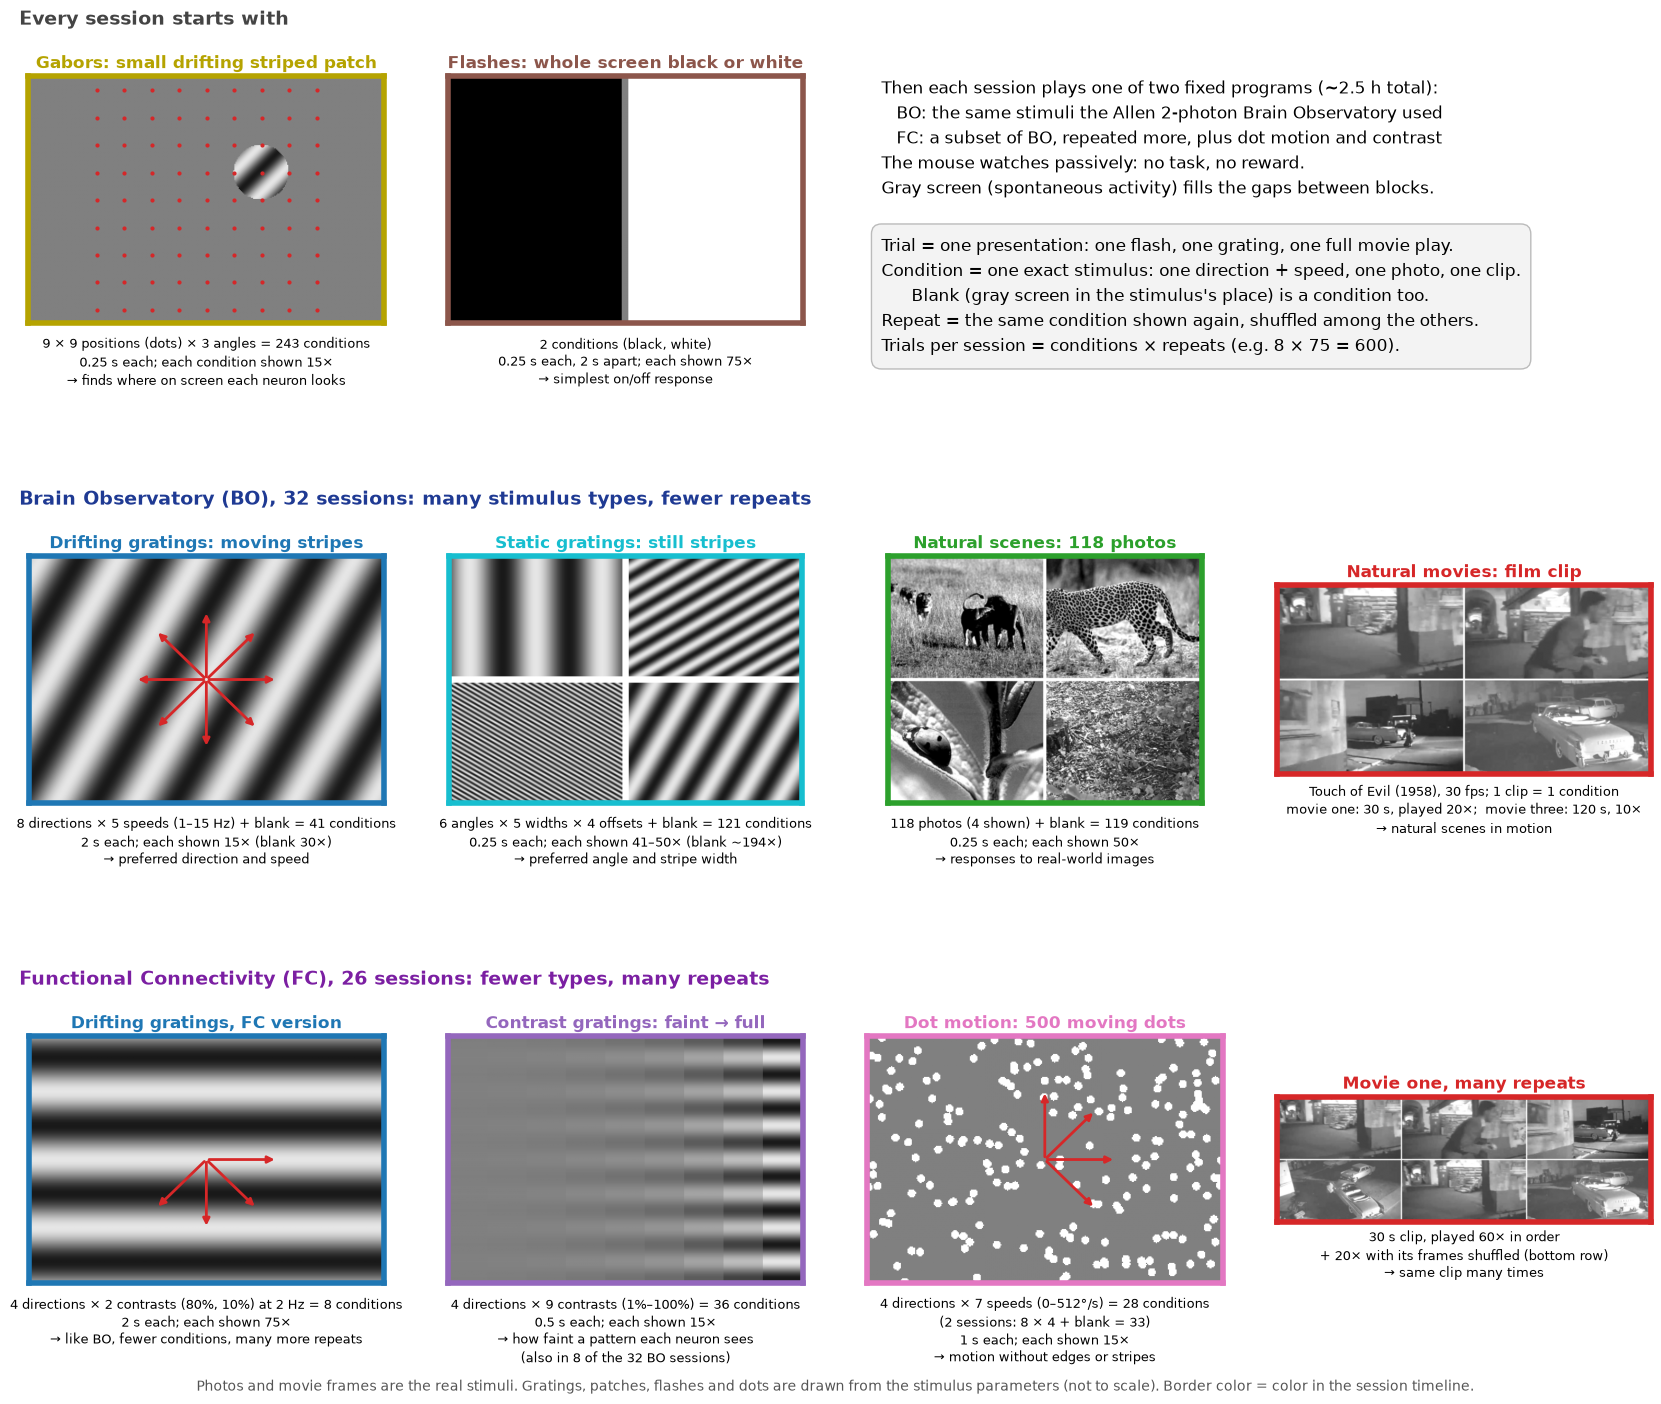

In [5]:
from PIL import Image

SAMPLES = TABLES / "stim_samples"
STIM_COLOR = {
    "gabors": "#b5a300", "flashes": "#8c564b", "drifting_gratings": "#1f77b4", "static_gratings": "#17becf",
    "natural_scenes": "#2ca02c", "natural_movie_one": "#d62728", "natural_movie_three": "#ff7f0e",
    "drifting_gratings_contrast": "#9467bd", "dot_motion": "#e377c2", "natural_movie_one_shuffled": "#f4a6a6",
    "spontaneous": "#d9d9d9",
}
# FC variants of a BO stimulus share its color
STIM_COLOR["drifting_gratings_75_repeats"] = STIM_COLOR["drifting_gratings"]
STIM_COLOR["natural_movie_one_more_repeats"] = STIM_COLOR["natural_movie_one"]

# Schematic screen: 130 x 90 degrees of visual angle at 2.5 px/deg
W, H = 325, 225
SX, SY = np.meshgrid(np.linspace(-65, 65, W), np.linspace(45, -45, H))


def grating(ori_deg, sf=0.04, contrast=0.8, phase=0.0):
    t = -np.deg2rad(ori_deg)  # angles run clockwise from 0° = rightward (whitepaper), so 90° = downward
    return 0.5 + 0.5 * contrast * np.cos(2 * np.pi * sf * (SX * np.cos(t) + SY * np.sin(t)) + phase)


def mosaic(images, ncols, pad=6):
    h, w = images[0].shape
    nrows = int(np.ceil(len(images) / ncols))
    out = np.ones((nrows * h + (nrows - 1) * pad, ncols * w + (ncols - 1) * pad))
    for i, im in enumerate(images):
        r, c = divmod(i, ncols)
        out[r * (h + pad): r * (h + pad) + h, c * (w + pad): c * (w + pad) + w] = im
    return out


def direction_arrows(ax, angles):
    for a in -np.deg2rad(angles):  # clockwise, like grating()
        ax.annotate("", xy=(0.5 + 0.2 * np.cos(a), 0.5 + 0.28 * np.sin(a)), xytext=(0.5, 0.5),
                    xycoords="axes fraction", arrowprops=dict(arrowstyle="-|>", color="C3", lw=2))


def stim_tile(ax, img, key, title, lines):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1, interpolation="bilinear")
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color(STIM_COLOR[key])
        s.set_linewidth(4)
    ax.set_title(title, fontsize=12, fontweight="bold", color=STIM_COLOR[key], pad=6)
    ax.text(0.5, -0.05, "\n".join(lines), transform=ax.transAxes, ha="center", va="top", fontsize=9.5,
            linespacing=1.35)


gabor = np.full((H, W), 0.5)
patch = (SX - 20) ** 2 + (SY - 10) ** 2 < 10 ** 2  # 20 deg circular mask
gabor[patch] = grating(45, sf=0.08)[patch]
flash = np.zeros((H, W))
flash[:, W // 2:] = 1
flash[:, W // 2 - 3: W // 2 + 3] = 0.5
dots = np.full((H, W), 0.5)
rng = np.random.default_rng(0)
for x, y in zip(rng.uniform(-65, 65, 200), rng.uniform(-45, 45, 200)):
    dots[(SX - x) ** 2 + (SY - y) ** 2 < 1.5 ** 2] = 1.0
contrasts = np.array([0.01, 0.02, 0.04, 0.08, 0.13, 0.2, 0.35, 0.6, 1.0])
strip = np.minimum(((SX + 65) / 130 * len(contrasts)).astype(int), len(contrasts) - 1)
contrast_steps = 0.5 + (grating(90, sf=0.08) - 0.5) * contrasts[strip]
static = mosaic([grating(o, sf=f, phase=p)[::2, ::2] for o, f, p in [(0, 0.02, 0), (60, 0.08, 1), (120, 0.32, 2),
                                                                   (30, 0.04, 3)]], 2)
scenes = [np.asarray(Image.open(SAMPLES / f"natural_scene_{i}.tiff").convert("L").resize((294, 230))) / 255
          for i in (5, 17, 42, 88)]
frames = np.load(SAMPLES / "natural_movie_one_frames.npy") / 255  # movie one frames 0, 150, ..., 750

fig = plt.figure(figsize=(17, 14.8))
gs = fig.add_gridspec(3, 4, hspace=0.95, wspace=0.12, left=0.02, right=0.98, top=0.9, bottom=0.085)
tiles = [
    (0, 0, gabor, "gabors", "Gabors: small drifting striped patch",
     ["9 × 9 positions (dots) × 3 angles = 243 conditions", "0.25 s each; each condition shown 15×",
      "→ finds where on screen each neuron looks"], None),
    (0, 1, flash, "flashes", "Flashes: whole screen black or white",
     ["2 conditions (black, white)", "0.25 s each, 2 s apart; each shown 75×", "→ simplest on/off response"], None),
    (1, 0, grating(30), "drifting_gratings", "Drifting gratings: moving stripes",
     ["8 directions × 5 speeds (1–15 Hz) + blank = 41 conditions", "2 s each; each shown 15× (blank 30×)",
      "→ preferred direction and speed"], range(0, 360, 45)),
    (1, 1, static, "static_gratings", "Static gratings: still stripes",
     ["6 angles × 5 widths × 4 offsets + blank = 121 conditions", "0.25 s each; each shown 41–50× (blank ~194×)",
      "→ preferred angle and stripe width"], None),
    (1, 2, mosaic(scenes, 2), "natural_scenes", "Natural scenes: 118 photos",
     ["118 photos (4 shown) + blank = 119 conditions", "0.25 s each; each shown 50×",
      "→ responses to real-world images"], None),
    (1, 3, mosaic(list(frames[:4]), 2), "natural_movie_one", "Natural movies: film clip",
     ["Touch of Evil (1958), 30 fps; 1 clip = 1 condition", "movie one: 30 s, played 20×;  movie three: 120 s, 10×",
      "→ natural scenes in motion"], None),
    (2, 0, grating(90), "drifting_gratings_75_repeats", "Drifting gratings, FC version",
     ["4 directions × 2 contrasts (80%, 10%) at 2 Hz = 8 conditions", "2 s each; each shown 75×",
      "→ like BO, fewer conditions, many more repeats"], [0, 45, 90, 135]),
    (2, 1, contrast_steps, "drifting_gratings_contrast", "Contrast gratings: faint → full",
     ["4 directions × 9 contrasts (1%–100%) = 36 conditions", "0.5 s each; each shown 15×",
      "→ how faint a pattern each neuron sees", "(also in 8 of the 32 BO sessions)"], None),
    (2, 2, dots, "dot_motion", "Dot motion: 500 moving dots",
     ["4 directions × 7 speeds (0–512°/s) = 28 conditions", "(2 sessions: 8 × 4 + blank = 33)", "1 s each; each shown 15×",
      "→ motion without edges or stripes"],
     [-a for a in (-45, 0, 45, 90)]),  # dot Dir runs counterclockwise (Allen forum), gratings clockwise
    (2, 3, mosaic([frames[i] for i in (0, 1, 2, 4, 0, 3)], 3), "natural_movie_one_more_repeats",
     "Movie one, many repeats",
     ["30 s clip, played 60× in order", "+ 20× with its frames shuffled (bottom row)", "→ same clip many times"],
     None),
]
for r, c, img, key, title, lines, angles in tiles:
    ax = fig.add_subplot(gs[r, c])
    stim_tile(ax, img, key, title, lines)
    if angles is not None:
        direction_arrows(ax, angles)
    if key == "gabors":
        gx, gy = np.meshgrid(np.arange(-40, 41, 10), np.arange(-40, 41, 10))
        ax.scatter((gx.ravel() + 65) * 2.5, (45 - gy.ravel()) * 2.5, s=4, c="C3")
        ax.set(xlim=(0, W - 1), ylim=(H - 1, 0))

ax = fig.add_subplot(gs[0, 2:])
ax.axis("off")
ax.text(0.03, 1.0,
        "Then each session plays one of two fixed programs (~2.5 h total):\n"
        "   BO: the same stimuli the Allen 2-photon Brain Observatory used\n"
        "   FC: a subset of BO, repeated more, plus dot motion and contrast\n"
        "The mouse watches passively: no task, no reward.\n"
        "Gray screen (spontaneous activity) fills the gaps between blocks.",
        fontsize=12, va="top", linespacing=1.5)
ax.text(0.03, 0.36,
        "Trial = one presentation: one flash, one grating, one full movie play.\n"
        "Condition = one exact stimulus: one direction + speed, one photo, one clip.\n"
        "      Blank (gray screen in the stimulus's place) is a condition too.\n"
        "Repeat = the same condition shown again, shuffled among the others.\n"
        "Trials per session = conditions × repeats (e.g. 8 × 75 = 600).",
        fontsize=12, va="top", linespacing=1.5,
        bbox=dict(boxstyle="round,pad=0.6", fc="#f3f3f3", ec="#bbbbbb"))

rows = [("Every session starts with", "#444444"),
        (f"Brain Observatory (BO), {(sessions.session_type == BO).sum()} sessions: many stimulus types, fewer repeats",
         "#1f3a93"),
        (f"Functional Connectivity (FC), {(sessions.session_type == FC).sum()} sessions: fewer types, many repeats",
         "#7b1fa2")]
for r, (label, color) in enumerate(rows):
    top = max(a.get_position().y1 for a in fig.axes if a.get_subplotspec().rowspan.start == r and a.images)
    fig.text(0.02, top + 0.035, label, fontsize=14, fontweight="bold", color=color)
fig.text(0.5, 0.012, "Photos and movie frames are the real stimuli. Gratings, patches, flashes and dots are drawn "
         "from the stimulus parameters (not to scale). Border color = color in the session timeline.",
         ha="center", fontsize=10, color="#555555")
fig.savefig(FIGURE_DIR / "allen_stimuli.png", dpi=150)
plt.show()

### Session timeline

- One BO and one FC session from start to end.
- Colors match the stimulus gallery. Gray = gray screen (spontaneous activity).
- Both types share the first ~26 min. After that:
  - BO cycles through many stimuli in short blocks.
  - FC repeats a few stimuli.
- The FC example is typical: 24 of 26 FC sessions show 4 dot directions.

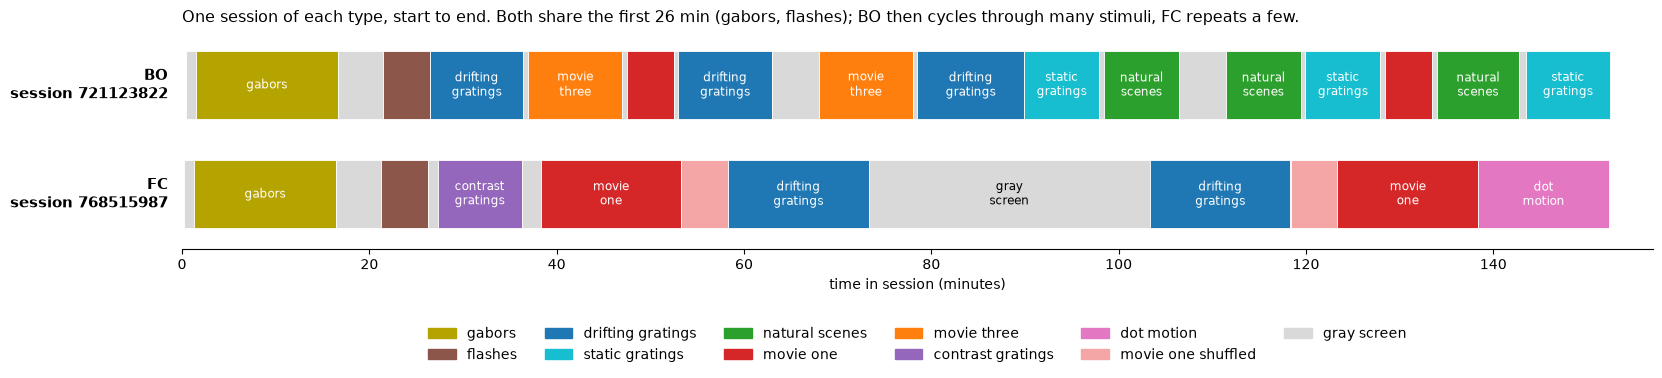

In [6]:
STIM_NAME = {
    "gabors": "gabors", "flashes": "flashes", "drifting_gratings": "drifting gratings",
    "drifting_gratings_75_repeats": "drifting gratings", "static_gratings": "static gratings",
    "natural_scenes": "natural scenes", "natural_movie_one": "movie one", "natural_movie_one_more_repeats": "movie one",
    "natural_movie_three": "movie three", "natural_movie_one_shuffled": "movie one shuffled",
    "drifting_gratings_contrast": "contrast gratings", "dot_motion": "dot motion", "spontaneous": "gray screen",
}


def stimulus_blocks(session_id):
    """Consecutive presentations of the same stimulus merged into one block, in minutes."""
    x = stimuli[stimuli.session_id == session_id].sort_values("start_time")
    run = (x.stimulus != x.stimulus.shift()).cumsum()
    b = x.groupby(run).agg(stim=("stimulus", "first"), t0=("start_time", "min"), t1=("stop_time", "max"))
    return b.assign(t0=b.t0 / 60, t1=b.t1 / 60)


bo = sessions[sessions.session_type == BO].session_id.iloc[0]
dot_dirs = stimuli[stimuli.stimulus == "dot_motion"].groupby("session_id").Dir.nunique()
fc = dot_dirs[dot_dirs == 4].index[0]

fig, ax = plt.subplots(figsize=(17, 4.2))
for y, (label, sid) in zip((1, 0), [("BO", bo), ("FC", fc)]):
    for b in stimulus_blocks(sid).itertuples():
        ax.barh(y, b.t1 - b.t0, left=b.t0, height=0.62, color=STIM_COLOR[b.stim], edgecolor="white", lw=0.6)
        if b.t1 - b.t0 >= 7.5:
            name = STIM_NAME[b.stim].replace(" ", "\n")
            dark = b.stim not in ("spontaneous", "natural_movie_one_shuffled")
            ax.text((b.t0 + b.t1) / 2, y, name, ha="center", va="center", fontsize=8.5, color="w" if dark else "k")
    ax.text(-1.5, y, f"{label}\nsession {sid}", ha="right", va="center", fontsize=11, fontweight="bold")
ax.set(xlim=(0, 157), ylim=(-0.5, 1.5), yticks=[], xlabel="time in session (minutes)")
for s in ("left", "right", "top"):
    ax.spines[s].set_visible(False)
shown = ["gabors", "flashes", "drifting_gratings", "static_gratings", "natural_scenes", "natural_movie_one",
         "natural_movie_three", "drifting_gratings_contrast", "dot_motion", "natural_movie_one_shuffled",
         "spontaneous"]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=STIM_COLOR[k]) for k in shown], [STIM_NAME[k] for k in shown],
          loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=6, frameon=False, fontsize=10)
ax.set_title("One session of each type, start to end. Both share the first 26 min (gabors, flashes); BO then "
             "cycles through many stimuli, FC repeats a few.", fontsize=11.5, loc="left")
fig.subplots_adjust(left=0.125, right=0.99, top=0.88, bottom=0.36)
fig.savefig(FIGURE_DIR / "allen_session_timeline.png", dpi=150)
plt.show()

### Neurons per session

- QC units per session (AllenSDK default), bars stacked by session type.
- All-unit counts (including the units Allen labels noise) are in the per-session table above.

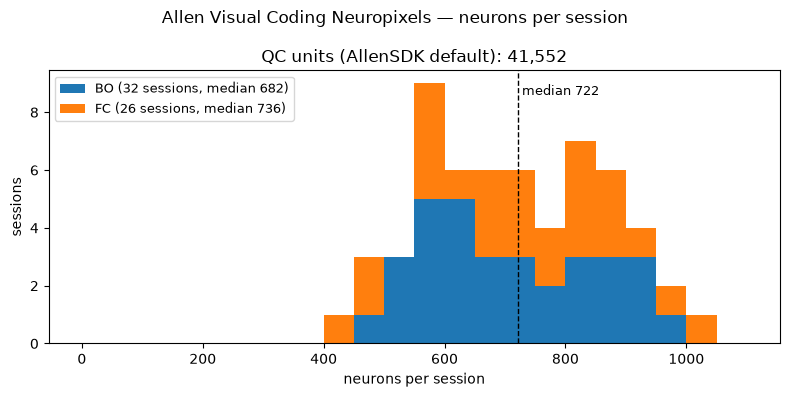

In [7]:
def half_up(x):
    return int(np.floor(x + 0.5))


def median_line(ax, values, color="k"):
    m = float(np.median(values))
    ax.axvline(m, color=color, ls="--", lw=1)
    ax.text(m, ax.get_ylim()[1] * 0.95, f" median {half_up(m):,}", color=color, va="top", fontsize=9)


fig, ax = plt.subplots(figsize=(8, 4))
groups = [sessions.loc[sessions.session_type == t, "qc_units"] for t in (BO, FC)]
ax.hist(groups, bins=np.arange(0, 1101, 50), stacked=True, color=[TYPE_COLOR[BO], TYPE_COLOR[FC]],
        label=[f"{SHORT[t]} ({len(g)} sessions, median {half_up(g.median())})" for t, g in zip((BO, FC), groups)])
ax.set(title=f"QC units (AllenSDK default): {sessions.qc_units.sum():,}", xlabel="neurons per session",
       ylabel="sessions")
median_line(ax, sessions.qc_units)
ax.legend(fontsize=9, loc="upper left")
fig.suptitle("Allen Visual Coding Neuropixels — neurons per session")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "allen_neurons_per_session.png", dpi=150)
plt.show()

### Firing rates

- One rate per QC unit: NWB `firing_rate`, spikes over the whole session.
- Bars stacked by session type.
- The QC presence-ratio cut removes most of the very low-rate units.
- Rates of all units (including noise) are in the table below.

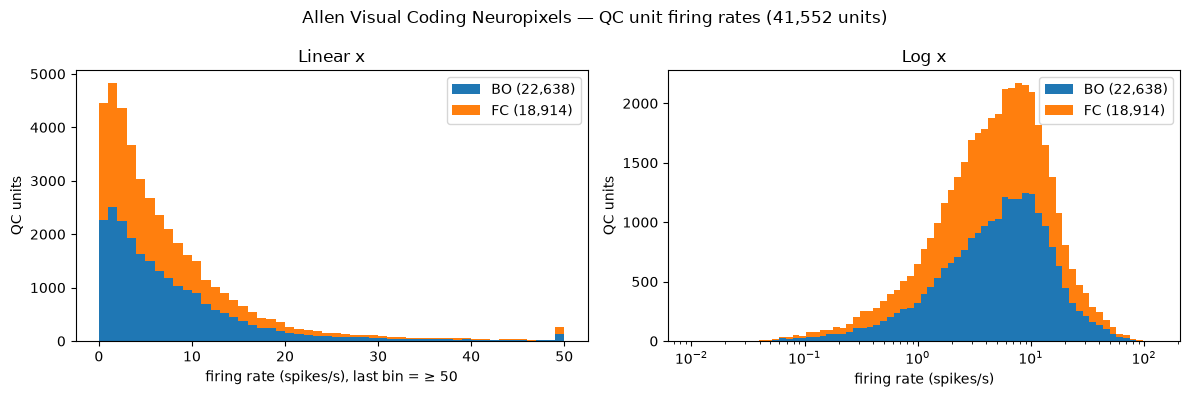

,units,mean Hz,median Hz
all all,136556.0,4.79,2.77
all BO,74658.0,4.93,2.93
all FC,61898.0,4.62,2.58
QC all,41552.0,7.72,5.15
QC BO,22638.0,7.93,5.52
QC FC,18914.0,7.47,4.76


In [8]:
fr = units.firing_rate
qc = {t: fr[units.qc & (units.type == t)] for t in (BO, FC)}
colors = [TYPE_COLOR[t] for t in qc]
labels = [f"{SHORT[t]} ({len(q):,})" for t, q in qc.items()]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.hist([q.clip(upper=50) for q in qc.values()], bins=np.arange(0, 51, 1), stacked=True, color=colors, label=labels)
ax.set(xlabel="firing rate (spikes/s), last bin = ≥ 50", ylabel="QC units", title="Linear x")
ax.legend()
ax = axes[1]
pos = [q[q > 0] for q in qc.values()]
bins = np.logspace(np.floor(np.log10(min(p.min() for p in pos))), np.log10(max(p.max() for p in pos)) + 0.05, 70)
ax.hist(pos, bins=bins, stacked=True, color=colors, label=labels)
ax.set_xscale("log")
ax.set(xlabel="firing rate (spikes/s)", ylabel="QC units", title="Log x")
ax.legend()
fig.suptitle(f"Allen Visual Coding Neuropixels — QC unit firing rates ({units.qc.sum():,} units)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "allen_firing_rates.png", dpi=150)
plt.show()

display(pd.DataFrame({
    f"{name} {SHORT.get(t, 'all')}": {"units": int(m.sum()), "mean Hz": fr[m].mean(), "median Hz": fr[m].median()}
    for name, mask in [("all", fr.notna()), ("QC", units.qc)]
    for t, m in [("all", mask), (BO, mask & (units.type == BO)), (FC, mask & (units.type == FC))]
}).T.round(2))

### Trials by stimulus

- Every session of a type runs the same fixed protocol. The only variations:
  - 8 of the 32 BO sessions add a drifting-gratings-contrast block.
  - 2 FC sessions show dot motion in 8 directions instead of 4.
  - A few sessions lose some presentations.
- So the session type sets which stimuli a session has, and how many. A table shows this better than a
  per-session plot.

**Columns**

- **conditions**: distinct stimuli. Each one is one exact parameter combination.
  - Example: drifting gratings = 8 directions × 5 temporal frequencies = 40, plus blank = 41.
  - Blank (a gray screen in place of the stimulus) is its own condition.
- **trials / condition**: how many times one session shows one condition.
  - Blank is in brackets when its count differs.
  - Static gratings are drawn in random order, so their count varies by grating (41–50).
- **trials / session**: every presentation of the stimulus in one session (conditions × trials / condition).
- **on (s)**: how long one trial is on screen.
- **ITI (s)**: the gap before the next trial (0 = back to back).
- **min / session**: time the stimulus takes per session.
  - Measured from first onset to last offset of each of its blocks, so the gaps count.
  - The 250 ms stimuli dominate the trial counts but not the time.
- **trials, all sessions**: sum over every session of the type that shows the stimulus.

Per-session values are from the median session. Exceptions are in brackets.

**Movies**

- The whole clip is one condition. One play of it is one trial.
  - Example: natural movie one in BO is 1 condition × 20 trials (the same 30 s clip, played 20 times
    back to back).
  - So the mouse sees every moment of the clip 20 times.
- To treat a movie as many conditions, split it into frames (900 frames × 20 repeats) or short segments.

In [9]:
STIM_ORDER = ["flashes", "drifting_gratings", "drifting_gratings_contrast", "drifting_gratings_75_repeats",
              "static_gratings", "gabors", "dot_motion", "natural_scenes", "natural_movie_one",
              "natural_movie_one_more_repeats", "natural_movie_one_shuffled", "natural_movie_three", "spontaneous"]
STIM_LABEL = {
    "flashes": "flashes", "drifting_gratings": "drifting gratings", "drifting_gratings_contrast": "gratings × contrast",
    "drifting_gratings_75_repeats": "drifting gratings, 75 repeats", "static_gratings": "static gratings",
    "gabors": "gabors", "dot_motion": "dot motion", "natural_scenes": "natural scenes",
    "natural_movie_one": "natural movie one", "natural_movie_one_more_repeats": "natural movie one, more repeats",
    "natural_movie_one_shuffled": "natural movie one, shuffled", "natural_movie_three": "natural movie three",
    "spontaneous": "gray screen",
}
STIM_WHAT = {
    "flashes": "whole screen turns white or black",
    "drifting_gratings": "moving stripes; 8 directions × 5 temporal frequencies (1–15 Hz) + blank",
    "drifting_gratings_contrast": "moving stripes; 4 directions × 9 contrasts",
    "drifting_gratings_75_repeats": "moving stripes; 4 directions × 2 contrasts (80%, 10%) at 2 Hz",
    "static_gratings": "still stripes; 6 orientations × 5 spatial frequencies × 4 phases + blank",
    "gabors": "small striped patch; 9 × 9 grid of positions × 3 orientations (maps receptive fields)",
    "dot_motion": "field of 500 moving dots; 4 directions × 7 speeds, 0–512°/s (2 sessions: 8 × 4 + blank)",
    "natural_scenes": "118 still photographs + blank",
    "natural_movie_one": "30 s black-and-white film clip (one trial = one full playthrough)",
    "natural_movie_one_more_repeats": "the same 30 s clip, more repeats",
    "natural_movie_one_shuffled": "the same clip with its frames in shuffled order",
    "natural_movie_three": "120 s film clip",
    "spontaneous": "gray screen, no stimulus (not a trial)",
}
assert set(stimuli.stimulus) == set(STIM_ORDER)

# A condition is one combination of stimulus parameters. Blank (a gray screen in place of the stimulus: every
# parameter empty, or frame -1 for natural scenes) is its own condition, and one movie clip is one condition.
PARAMS = ["orientation", "temporal_frequency", "spatial_frequency", "contrast", "color",
          "x_position", "y_position", "phase", "Dir", "Speed", "frame"]
movie = stimuli.stimulus.str.startswith("natural_movie")
stimuli["blank"] = ~movie & stimuli[PARAMS[:-1]].isna().all(axis=1) & (stimuli.frame.isna() | (stimuli.frame == -1))
stimuli["condition"] = stimuli.groupby(["stimulus", *PARAMS], dropna=False).ngroup().where(~movie, -1)
stimuli["minutes"] = (stimuli.stop_time - stimuli.start_time) / 60

KEY = ["type", "stimulus", "session_id"]
per_session = stimuli.groupby(KEY).agg(trials=("minutes", "size"), trial_s=("minutes", lambda m: m.median() * 60))
# ITI: gap from one trial's end to the next trial's start in the same block (0 = back to back)
order = stimuli.sort_values(["session_id", "start_time"])
stimuli["iti_s"] = order.groupby(["session_id", "stimulus", "block"]).start_time.shift(-1) - order.stop_time
per_session["iti_s"] = stimuli.groupby(KEY).iti_s.median()
# Time a stimulus takes: first onset to last offset of each of its blocks, so the gray gaps between flashes,
# gratings and dots count. Gray-screen rows are separate periods, so those are summed instead.
blocks = stimuli.groupby([*KEY, "block"]).agg(t0=("start_time", "min"), t1=("stop_time", "max"))
per_session["minutes"] = ((blocks.t1 - blocks.t0) / 60).groupby(KEY).sum()
spont = per_session.index.get_level_values("stimulus") == "spontaneous"
per_session.loc[spont, "minutes"] = stimuli.groupby(KEY).minutes.sum()[spont]

counts = stimuli.groupby([*KEY, "condition"]).agg(n=("blank", "size"), blank=("blank", "first")).reset_index()
full, blank = counts[~counts.blank], counts[counts.blank]
per_session["conditions"] = full.groupby(KEY).size().add(blank.groupby(KEY).size(), fill_value=0).astype(int)
per_session["repeats"] = full.groupby(KEY).n.median()
per_session["repeats_min"] = full.groupby(KEY).n.min()
per_session["repeats_max"] = full.groupby(KEY).n.max()
per_session["blank_repeats"] = blank.groupby(KEY).n.sum()
assert per_session.minutes.notna().all()
assert trial_stims.groupby("session_id").size().reindex(sessions.session_id).to_numpy().tolist() \
    == sessions.trials.tolist()


def usual(values, fmt="{:,.0f}"):
    """The value most sessions share, with the exceptions in brackets."""
    vc = values.value_counts()
    rest = [f"{n} sessions: {fmt.format(v)}" for v, n in vc.iloc[1:].items()]
    return fmt.format(vc.index[0]) + (f" ({'; '.join(rest)})" if rest else "")


def repeats_text(d, unit=""):
    """Median repeats of one condition per session, e.g. "15 (blank 30)" or "49 (41–50; blank 194)"; `unit`
    goes before the brackets. The range shows when most sessions vary by condition."""
    r = d.repeats.median()
    extra = [f"{d.repeats_min.min():.0f}–{d.repeats_max.max():.0f}"] if d.repeats_min.median() < r else []
    b = d.blank_repeats.median()
    if not (np.isnan(b) or b == r):
        extra.append(f"blank {b:.0f}")
    return f"{r:.0f}{unit}" + (f" ({'; '.join(extra)})" if extra else "")


def secs(x):
    """Seconds for the tables: 0.25, 1.75, 2, 30."""
    return f"{round(x, 2) if x < 10 else round(x):g}"


def stim_table(t):
    rows = []
    for stim in STIM_ORDER:
        if (t, stim) not in per_session.index.droplevel(2):
            continue
        d = per_session.loc[(t, stim)]
        movie, trial = stim.startswith("natural_movie"), stim != "spontaneous"
        rows.append({
            "stimulus": STIM_LABEL[stim], "sessions": len(d),
            "conditions": f"1 ({secs(d.trial_s.median())} s clip)" if movie else usual(d.conditions) if trial else "—",
            "trials / condition": f"{d.repeats.median():.0f} plays" if movie else repeats_text(d) if trial else "—",
            "trials / session": usual(d.trials) if trial else "—",
            "on (s)": secs(d.trial_s.median()) if trial else "—",
            "ITI (s)": secs(d.iti_s.median()) if trial else "—",
            "min / session": round(d.minutes.median(), 1),
            "trials, all sessions": f"{d.trials.sum():,}" if trial else "—",
        })
    s = sessions[sessions.session_type == t].trials
    rows.append({"stimulus": "all stimuli", "sessions": len(s), "conditions": "", "trials / condition": "",
                 "trials / session": f"{s.median():,.0f} [{s.min():,} – {s.max():,}]", "on (s)": "", "ITI (s)": "",
                 "min / session": round(per_session.loc[t].minutes.groupby(level="session_id").sum().median(), 1),
                 "trials, all sessions": f"{s.sum():,}"})
    return pd.DataFrame(rows).set_index("stimulus")

for t in (BO, FC):
    print(f"{SHORT[t]}: {t} ({(sessions.session_type == t).sum()} sessions)")
    display(stim_table(t))

BO: brain_observatory_1.1 (32 sessions)


,sessions,conditions,trials / condition,trials / session,on (s),ITI (s),min / session,"trials, all sessions"
stimulus,,,,,,,,
flashes,32,2,75,150,0.25,1.75,5.0,"4,800"
drifting gratings,32,41,15 (blank 30),630 (4 sessions: 628),2,1,31.5,"20,152"
gratings × contrast,8,36,15,540,0.5,0.5,9.0,"4,320"
static gratings,32,121,49 (41–50; blank 194),"6,000",0.25,0,25.0,"192,000"
gabors,32,243,15,"3,645",0.25,0,15.2,"116,640"
natural scenes,32,119,50,"5,950",0.25,0,24.8,"190,400"
natural movie one,32,1 (30 s clip),20 plays,20,30,0,10.0,640
natural movie three,32,1 (120 s clip),10 plays,10,120,0,20.0,320
gray screen,32,—,—,—,—,—,20.6,—


FC: functional_connectivity (26 sessions)


,sessions,conditions,trials / condition,trials / session,on (s),ITI (s),min / session,"trials, all sessions"
stimulus,,,,,,,,
flashes,26,2,75,150,0.25,1.75,5.0,"3,900"
gratings × contrast,26,36,15,540,0.5,0.5,9.0,"14,040"
"drifting gratings, 75 repeats",26,8,75,600,2,1,30.0,"15,600"
gabors,26,243,15,"3,645",0.25,0,15.2,"94,770"
dot motion,26,28 (2 sessions: 33),15,420 (2 sessions: 495),1,1,14.0,"11,070"
"natural movie one, more repeats",26,1 (30 s clip),60 plays,60,30,0,30.0,"1,560"
"natural movie one, shuffled",26,1 (30 s clip),20 plays,20,30,0,10.0,520
gray screen,26,—,—,—,—,—,38.9,—
all stimuli,26,,,"5,435 [5,435 – 5,510]",,,152.1,"141,460"


### Conditions × repeats

**Top: what a repeat is.**

- The first 30 FC drifting-grating trials of one session, in the order shown.
- Its 8 conditions (4 directions × 2 contrasts) come back in shuffled order.
- Each condition comes back 75 times per session.

**Bottom: one point per stimulus.**

- x = conditions per session; y = repeats of each condition per session. Log scales.
- Dotted diagonals mark trials per session (conditions × repeats).
- Gray = shown the same way in both types:
  - gabors and flashes open every session;
  - gratings × contrast runs in every FC session and in 8 of the 32 BO sessions.
- For dataset totals, multiply the repeats by the number of sessions that show the stimulus.
- **Result**: BO spreads its trials over many conditions with few repeats each. FC trades conditions for repeats.
  - Drifting gratings: 41 × 15 in BO, 8 × 75 in FC.
  - Natural movie one: 20 repeats in BO, 60 in FC.

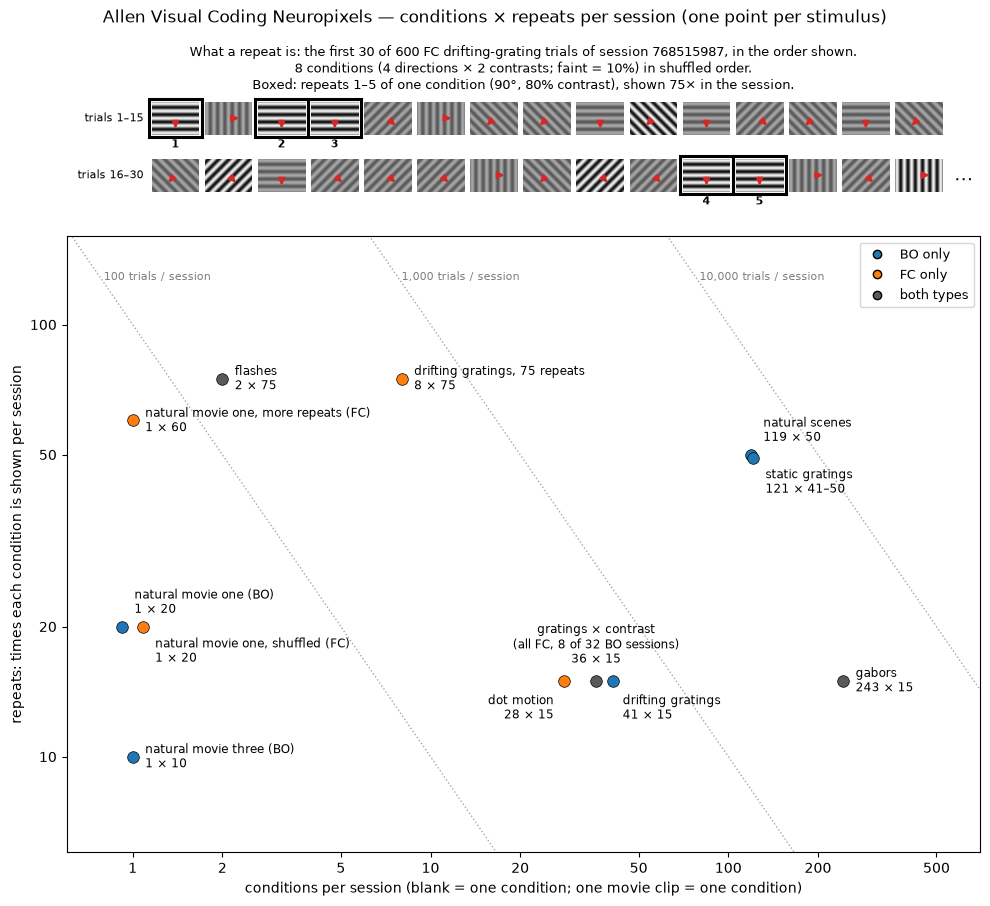

In [10]:
pts = (per_session.drop(index="spontaneous", level="stimulus").groupby(["type", "stimulus"])
       .agg(conditions=("conditions", lambda c: c.mode().iloc[0]), repeats=("repeats", "median"),
            lo=("repeats_min", "min"), lo_usual=("repeats_min", "median"), hi=("repeats_max", "max")).reset_index())
pts["repeats"] = pts.repeats.round()
# A stimulus shown the same way in both types becomes one gray point.
pts["both"] = pts.groupby(["stimulus", "conditions", "repeats"]).type.transform("nunique") == 2
pts = pts.drop_duplicates(["stimulus", "conditions", "repeats"]).reset_index(drop=True)
pts["color"] = np.where(pts.both, "0.35", pts.type.map(TYPE_COLOR))
# Different stimuli at the same point sit side by side.
same = pts.groupby(["conditions", "repeats"]).cumcount()
pts["x"] = pts.conditions * np.where(pts.duplicated(["conditions", "repeats"], keep=False), 0.92 + 0.16 * same, 1)
LABEL_AT = {  # text offset in points; the side sets the alignment
    "gabors": (9, 0), "natural_scenes": (9, 7), "static_gratings": (9, -7), "drifting_gratings": (7, -9),
    "drifting_gratings_contrast": (0, 10), "dot_motion": (-7, -9), "drifting_gratings_75_repeats": (9, 0),
    "flashes": (9, 0), "natural_movie_one": (9, 7), "natural_movie_one_shuffled": (9, -7),
    "natural_movie_three": (9, 0), "natural_movie_one_more_repeats": (9, 0),
}
assert set(pts.stimulus) == set(LABEL_AT)

fig, (top, ax) = plt.subplots(2, 1, figsize=(10, 9.2), gridspec_kw=dict(height_ratios=[1.35, 5]))
# What a repeat is: real trial order of one FC drifting-grating block, one boxed condition.
sid, stim, n_show, per_row, pick = 768515987, "drifting_gratings_75_repeats", 30, 15, (90.0, 0.8)
ex = stimuli[(stimuli.session_id == sid) & (stimuli.stimulus == stim)].sort_values("start_time")
n_all, n_rep = len(ex), int(((ex.orientation == pick[0]) & (ex.contrast == pick[1])).sum())
ex = ex.head(n_show).reset_index(drop=True)
cw, ch, gap = 0.9, 0.9 * H / W, 0.45  # one screen-shaped cell per trial; gap between rows
k = 0
for i, t in ex.iterrows():
    x, y = i % per_row, -(i // per_row) * (ch + gap)
    # sqrt keeps the 10% gratings visible (schematic, like the gallery)
    top.imshow(grating(t.orientation, sf=0.05, contrast=np.sqrt(t.contrast))[::3, ::3], cmap="gray", vmin=0, vmax=1,
               extent=(x, x + cw, y, y + ch), aspect="auto")
    a = -np.deg2rad(t.orientation)  # clockwise, like grating()
    top.annotate("", xy=(x + cw / 2 + 0.25 * np.cos(a), y + ch / 2 + 0.25 * np.sin(a)),
                 xytext=(x + cw / 2, y + ch / 2), arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.5))
    if (t.orientation, t.contrast) == pick:
        k += 1
        top.add_patch(plt.Rectangle((x - 0.05, y - 0.05), cw + 0.1, ch + 0.1, fill=False, ec="k", lw=2.2))
        top.text(x + cw / 2, y - 0.08, str(k), ha="center", va="top", fontsize=8, fontweight="bold")
for row in range(n_show // per_row):
    y = -row * (ch + gap) + ch / 2
    top.text(-0.15, y, f"trials {row * per_row + 1}–{(row + 1) * per_row}", ha="right", va="center", fontsize=8)
top.text(per_row, -(n_show // per_row - 1) * (ch + gap) + ch / 2, " …", fontsize=14, va="center")
top.set(xlim=(-1.6, per_row + 0.6), ylim=(-(n_show // per_row - 1) * (ch + gap) - gap, ch + 0.08),
        xticks=[], yticks=[])
top.set_aspect("equal")
for s in top.spines.values():
    s.set_visible(False)
top.set_title(f"What a repeat is: the first {n_show} of {n_all} FC drifting-grating trials of session {sid}, in the "
              f"order shown.\n8 conditions (4 directions × 2 contrasts; faint = 10%) in shuffled order.\nBoxed: "
              f"repeats 1–{k} of one condition ({pick[0]:.0f}°, {pick[1]:.0%} contrast), shown {n_rep}× in the session.",
              fontsize=9)
xs = np.logspace(np.log10(0.5), np.log10(700), 50)
for total in (100, 1_000, 10_000):
    ax.plot(xs, total / xs, ls=":", color="0.65", lw=1, zorder=0)
    ax.text(total / 125, 125, f"{total:,} trials / session", color="0.5", fontsize=8, ha="left", va="bottom")
for p in pts.itertuples():
    ax.scatter(p.x, p.repeats, s=70, color=p.color, edgecolor="k", lw=0.5, zorder=3)
    dx, dy = LABEL_AT[p.stimulus]
    name = STIM_LABEL[p.stimulus] + ("\n(all FC, 8 of 32 BO sessions)" if p.stimulus == "drifting_gratings_contrast"
                                     else f" ({SHORT[p.type]})" if not p.both and p.stimulus.startswith("natural_movie")
                                     else "")
    reps = f"{p.lo:.0f}–{p.hi:.0f}" if p.lo_usual < p.repeats else f"{p.repeats:.0f}"
    ax.annotate(f"{name}\n{p.conditions} × {reps}", (p.x, p.repeats), xytext=(dx, dy), textcoords="offset points",
                ha="left" if dx > 0 else "right" if dx < 0 else "center",
                va="center" if dy == 0 else "bottom" if dy > 0 else "top", fontsize=8.5)
ticks = [1, 2, 5, 10, 20, 50, 100, 200, 500]
ax.set(xscale="log", yscale="log", xlim=(0.6, 700), ylim=(6, 160), xticks=ticks, xticklabels=ticks,
       yticks=[10, 20, 50, 100], yticklabels=[10, 20, 50, 100],
       xlabel="conditions per session (blank = one condition; one movie clip = one condition)",
       ylabel="repeats: times each condition is shown per session")
ax.minorticks_off()
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, markeredgecolor="k", label=l) for c, l in
                   [(TYPE_COLOR[BO], "BO only"), (TYPE_COLOR[FC], "FC only"), ("0.35", "both types")]],
          loc="upper right", fontsize=9)
fig.suptitle("Allen Visual Coding Neuropixels — conditions × repeats per session (one point per stimulus)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "allen_conditions_x_repeats.png", dpi=150)
plt.show()

### Every condition

- One screen-shaped cell per condition, for every stimulus.
- Each cell shows its repeats, trials and timing (median per session).
- Gratings, gabors and dots are drawn from the stimulus-table parameters.
- Photos and movie frames are the real stimuli from `stim_samples/`.
- Directions:
  - Grating angles run clockwise from 0° = rightward (whitepaper).
  - Dot directions run counterclockwise (PsychoPy; Allen staff).

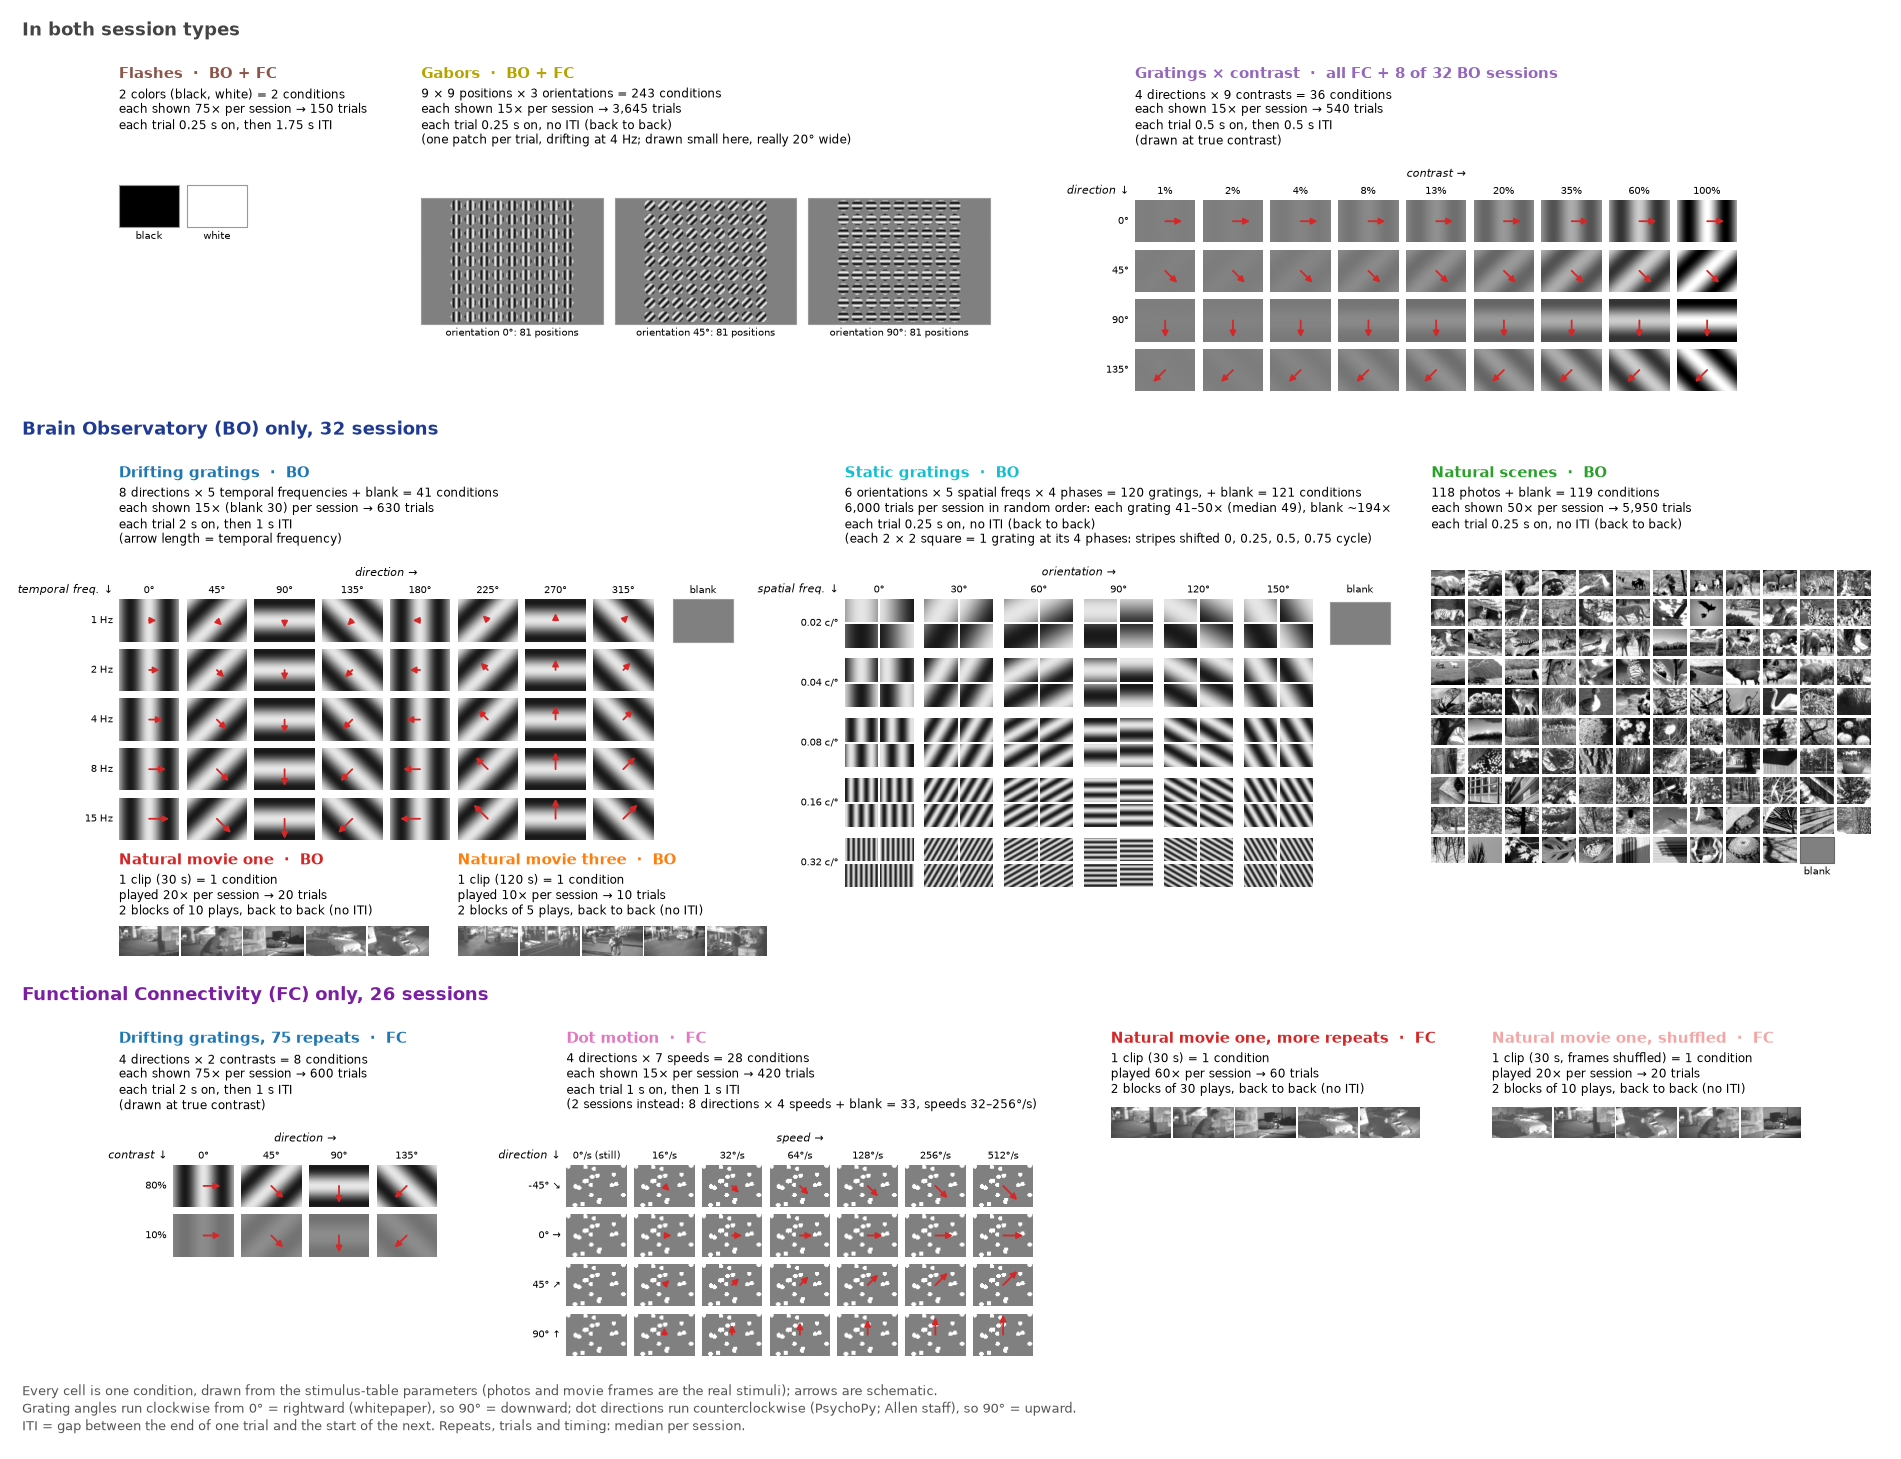

In [11]:
CW, CH, GAP = 1.0, 0.7, 0.12  # one screen-shaped cell per condition, in figure units
IX, IY = np.meshgrid(np.linspace(-20, 20, 60), np.linspace(14, -14, 42))  # a cell shows a 40° × 28° piece of screen
# Angles run clockwise from 0° = rightward motion / vertical bars (whitepaper), so 90° = downward: hence the minus signs.


def icon(ori=0.0, sf=0.04, contrast=0.8, phase=0.0, zoom=1.0):
    t = -np.deg2rad(ori)
    x, y = IX / zoom, IY / zoom
    return 0.5 + 0.5 * contrast * np.cos(2 * np.pi * (sf * (x * np.cos(t) + y * np.sin(t)) + phase))


rng = np.random.default_rng(1)
dot_icon = np.full(IX.shape, 0.5)
for x, y in zip(rng.uniform(-20, 20, 20), rng.uniform(-14, 14, 20)):
    dot_icon[(IX - x) ** 2 + (IY - y) ** 2 < 1.5 ** 2] = 1.0
GRAY = np.full((10, 14), 0.5)


def put(ax, img, x, y, w=CW, h=CH, edge=None):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1, extent=(x, x + w, y, y + h), interpolation="bilinear")
    if edge:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec=edge, lw=0.8))


def arrow(ax, x, y, deg, length, w=CW, h=CH):
    a = -np.deg2rad(deg)
    ax.annotate("", xy=(x + w / 2 + length * np.cos(a), y + h / 2 + length * np.sin(a)), xytext=(x + w / 2, y + h / 2),
                arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.3, shrinkA=0, shrinkB=0, mutation_scale=9))


def grid(ax, ox, oy, rows, cols, draw, row_title, col_title, cw=CW, ch=CH, gap=GAP):
    """Cells at (ox + c * (cw + gap), oy - r * (ch + gap)); `draw(r, c, x, y)` fills one. Labels above and left."""
    px, py = cw + gap, ch + gap
    for r in range(len(rows)):
        for c in range(len(cols)):
            draw(r, c, ox + c * px, oy - r * py)
        ax.text(ox - 0.1, oy - r * py + ch / 2, rows[r], ha="right", va="center", fontsize=7.5)
    for c, lab in enumerate(cols):
        ax.text(ox + c * px + cw / 2, oy + ch + 0.06, lab, ha="center", va="bottom", fontsize=7.5)
    ax.text(ox + (len(cols) * px - gap) / 2, oy + ch + 0.34, col_title + " →", ha="center", va="bottom", fontsize=8,
            style="italic")
    ax.text(ox - 0.1, oy + ch + 0.06, row_title + " ↓", ha="right", va="bottom", fontsize=8, style="italic")


def blank_cell(ax, x, y, label="blank", ch=CH):
    put(ax, GRAY, x, y + (ch - CH) / 2, edge="0.6")
    ax.text(x + CW / 2, y + ch + 0.06, label, ha="center", va="bottom", fontsize=7.5)


TIMING = per_session.groupby(level="stimulus")[["trial_s", "iti_s"]].median()  # median session


def timing(stim):
    on, iti = TIMING.loc[stim]
    on = round(on, 2) if on < 1 else round(on)
    return f"each trial {on:g} s on, " + (f"then {round(iti, 2):g} s ITI" if iti > 0.01 else "no ITI (back to back)")


def header(ax, x, top, stim, who, what, t, extra=None, reps=None):
    """Panel title; then what varies = conditions, repeats per session → trials, trial timing, any extra note."""
    d = per_session.loc[(t, stim)]
    cond = d.conditions.mode().iloc[0]
    if stim.startswith("natural_movie"):
        r = d.repeats.median()
        blocks = stimuli[(stimuli.stimulus == stim) & (stimuli.session_id.isin(d.index))].groupby("session_id").block.nunique()
        lines = [what + " = 1 condition", f"played {r:.0f}× per session → {r:.0f} trials",
                 f"{blocks.median():.0f} blocks of {r / blocks.median():.0f} plays, back to back (no ITI)"]
    else:
        lines = [what + f" = {cond} condition" + "s" * bool(cond > 1),
                 reps or f"each shown {repeats_text(d, '×')} per session → {d.trials.median():,.0f} trials", timing(stim)]
    ax.text(x, top, f"{STIM_LABEL[stim].capitalize()}  ·  {who}", fontsize=10.5, fontweight="bold",
            color=STIM_COLOR[stim], va="top")
    ax.text(x, top - 0.32, "\n".join(lines + ([extra] if extra else [])), fontsize=8.5, va="top", linespacing=1.3)


def vals(stim, col):
    s = stimuli[(stimuli.stimulus == stim) & ~stimuli.blank]
    return np.sort(s[col].dropna().unique())


def filmstrip(ax, x, y, frames, w=1.0):
    h = w * frames.shape[1] / frames.shape[2]
    for k, f in enumerate(frames):
        put(ax, f, x + k * (w + 0.03), y - h, w=w, h=h)


def band(ax, y, text, color):
    ax.text(-1.6, y + 1.6, text, fontsize=13, fontweight="bold", color=color, va="bottom")


for stim in ["flashes", "gabors", "drifting_gratings_contrast"]:  # shared stimuli: the same in both types
    a, b = per_session.loc[(BO, stim)], per_session.loc[(FC, stim)]
    assert a.conditions.median() == b.conditions.median() and a.repeats.median() == b.repeats.median()

fig, ax = plt.subplots(figsize=(19, 15.3))
fig.subplots_adjust(left=0.005, right=0.995, top=0.995, bottom=0.005)

# ---- both session types: flashes, gabors, gratings × contrast
Y = 0.0
TOP = Y + 1.15
band(ax, Y, "In both session types", "#444444")
header(ax, 0, TOP, "flashes", "BO + FC", "2 colors (black, white)", FC)
for c, (v, lab) in enumerate([(0.0, "black"), (1.0, "white")]):
    put(ax, np.full((10, 14), v), c * (CW + GAP), Y - 1.5, edge="0.6")
    ax.text(c * (CW + GAP) + CW / 2, Y - 1.56, lab, ha="center", va="top", fontsize=7.5)

g_ori, g_x, g_y = vals("gabors", "orientation"), vals("gabors", "x_position"), vals("gabors", "y_position")
gx0 = 5.0
header(ax, gx0, TOP, "gabors", "BO + FC", f"{len(g_x)} × {len(g_y)} positions × {len(g_ori)} orientations", FC,
       extra="(one patch per trial, drifting at 4 Hz; drawn small here, really 20° wide)")
SXg, SYg = np.meshgrid(np.linspace(-65, 65, 260), np.linspace(45, -45, 180))
for k, o in enumerate(g_ori):
    t = -np.deg2rad(o)
    stripes = 0.5 + 0.45 * np.cos(2 * np.pi * 0.25 * (SXg * np.cos(t) + SYg * np.sin(t)))
    screen = np.full(SXg.shape, 0.5)
    for x in g_x:
        for y in g_y:
            m = (SXg - x) ** 2 + (SYg - y) ** 2 < 4 ** 2
            screen[m] = stripes[m]
    put(ax, screen, gx0 + k * 3.2, Y - 3.1, w=3.0, h=3.0 * 90 / 130, edge="0.6")
    ax.text(gx0 + k * 3.2 + 1.5, Y - 3.16, f"orientation {o:.0f}°: {len(g_x) * len(g_y)} positions", ha="center",
            va="top", fontsize=7.5)

c_dir, c_con = vals("drifting_gratings_contrast", "orientation"), vals("drifting_gratings_contrast", "contrast")
cx0 = 16.8
header(ax, cx0, TOP, "drifting_gratings_contrast", "all FC + 8 of 32 BO sessions",
       f"{len(c_dir)} directions × {len(c_con)} contrasts", FC, extra="(drawn at true contrast)")
grid(ax, cx0, Y - 1.75, [f"{d:.0f}°" for d in c_dir], [f"{c:.0%}" for c in c_con],
     lambda r, c, x, y: (put(ax, icon(c_dir[r], contrast=c_con[c]), x, y), arrow(ax, x, y, c_dir[r], 0.28)),
     "direction", "contrast")

# ---- BO only: drifting gratings, static gratings, natural scenes, movies
Y = -6.6
TOP = Y + 1.15
band(ax, Y, f"Brain Observatory (BO) only, {(sessions.session_type == BO).sum()} sessions", "#1f3a93")
d_dir, d_tf = vals("drifting_gratings", "orientation"), vals("drifting_gratings", "temporal_frequency")
header(ax, 0, TOP, "drifting_gratings", "BO", f"{len(d_dir)} directions × {len(d_tf)} temporal frequencies + blank",
       BO, extra="(arrow length = temporal frequency)")
lengths = np.linspace(0.12, 0.33, len(d_tf))
grid(ax, 0, Y - 1.75, [f"{f:g} Hz" for f in d_tf], [f"{d:.0f}°" for d in d_dir],
     lambda r, c, x, y: (put(ax, icon(d_dir[c]), x, y), arrow(ax, x, y, d_dir[c], lengths[r])),
     "temporal freq.", "direction")
blank_cell(ax, len(d_dir) * (CW + GAP) + 0.2, Y - 1.75)

s_ori, s_sf, s_ph = (vals("static_gratings", c) for c in ["orientation", "spatial_frequency", "phase"])
sx0, sw, sh, sg = 12.0, 0.55, 0.385, 0.04  # each cell: its 4 phases in a 2 × 2 square
scw, sch = 2 * sw + sg, 2 * sh + sg
d = per_session.loc[(BO, "static_gratings")]
header(ax, sx0, TOP, "static_gratings", "BO",
       f"{len(s_ori)} orientations × {len(s_sf)} spatial freqs × {len(s_ph)} phases = "
       f"{len(s_ori) * len(s_sf) * len(s_ph)} gratings, + blank", BO,
       reps=f"{d.trials.median():,.0f} trials per session in random order: each grating "
            f"{d.repeats_min.min():.0f}–{d.repeats_max.max():.0f}× (median {d.repeats.median():.0f}), blank "
            f"~{d.blank_repeats.median():.0f}×",
       extra="(each 2 × 2 square = 1 grating at its 4 phases: stripes shifted "
             + ", ".join(f"{p:g}" for p in s_ph) + " cycle)")


def static_cell(r, c, x, y):
    for k, p in enumerate(s_ph):
        put(ax, icon(s_ori[c], sf=s_sf[r], phase=p, zoom=2), x + (k % 2) * (sw + sg), y + (1 - k // 2) * (sh + sg),
            w=sw, h=sh)


grid(ax, sx0, Y - 1.85, [f"{f:g} c/°" for f in s_sf], [f"{o:.0f}°" for o in s_ori], static_cell, "spatial freq.",
     "orientation", cw=scw, ch=sch, gap=0.18)
blank_cell(ax, sx0 + len(s_ori) * (scw + 0.18) + 0.1, Y - 1.85, ch=sch)

thumbs = np.load(SAMPLES / "natural_scene_thumbs.npy") / 255
n_img = int((vals("natural_scenes", "frame") >= 0).sum())  # frame -1 = blank
assert n_img == len(thumbs)
nx0, tw, tg, per_row = 21.7, 0.56, 0.05, 12
th = tw * thumbs.shape[1] / thumbs.shape[2]
header(ax, nx0, TOP, "natural_scenes", "BO", f"{n_img} photos + blank", BO)
for i in range(n_img + 1):
    r, c = divmod(i, per_row)
    x, y = nx0 + c * (tw + tg), Y - 1.0 - r * (th + tg)
    put(ax, thumbs[i] if i < n_img else GRAY, x, y, w=tw, h=th, edge="0.4" if i == n_img else None)
ax.text(x + tw / 2, y - 0.05, "blank", ha="center", va="top", fontsize=7.5)

frames1 = np.load(SAMPLES / "natural_movie_one_frames.npy") / 255
frames3 = np.load(SAMPLES / "natural_movie_three_frames.npy") / 255
for k, (stim, frames, secs) in enumerate([("natural_movie_one", frames1, 30), ("natural_movie_three", frames3, 120)]):
    header(ax, k * 5.6, Y - 5.25, stim, "BO", f"1 clip ({secs} s)", BO)
    filmstrip(ax, k * 5.6, Y - 6.45, frames[:5])

# ---- FC only: drifting gratings 75 repeats, dot motion, movie one variants
Y = -15.95
TOP = Y + 1.15
band(ax, Y, f"Functional Connectivity (FC) only, {(sessions.session_type == FC).sum()} sessions", "#7b1fa2")
f_dir, f_con = vals("drifting_gratings_75_repeats", "orientation"), vals("drifting_gratings_75_repeats", "contrast")[::-1]
header(ax, 0, TOP, "drifting_gratings_75_repeats", "FC", f"{len(f_dir)} directions × {len(f_con)} contrasts", FC,
       extra="(drawn at true contrast)")
grid(ax, 0.9, Y - 1.75, [f"{c:.0%}" for c in f_con], [f"{d:.0f}°" for d in f_dir],
     lambda r, c, x, y: (put(ax, icon(f_dir[c], contrast=f_con[r]), x, y), arrow(ax, x, y, f_dir[c], 0.28)),
     "contrast", "direction")

dots = per_session.loc[(FC, "dot_motion")]
usual_ids = dots.index[dots.conditions == dots.conditions.mode().iloc[0]]
dm = stimuli[(stimuli.stimulus == "dot_motion") & ~stimuli.blank]
m_dir, m_sp = (np.sort(dm[dm.session_id.isin(usual_ids)][c].dropna().unique()) for c in ["Dir", "Speed"])
other = dm[~dm.session_id.isin(usual_ids)]
o_dir, o_sp = other.Dir.nunique(), other.Speed.nunique()
# Dot `Dir` runs counterclockwise (PsychoPy DotStim), unlike the gratings; table speeds in °/s per Allen staff:
# community.brain-map.org/t/dot-motion-stimulus-info-for-speed-doesnt-match-documented-stimulus-info/465
DEG_PER_S = {0: 0, 0.0005: 16, 0.001: 32, 0.005: 64, 0.01: 128, 0.02: 256, 0.04: 512}
assert set(dm.Speed.dropna()) <= set(DEG_PER_S)
mx0 = 7.4
header(ax, mx0, TOP, "dot_motion", "FC", f"{len(m_dir)} directions × {len(m_sp)} speeds", FC,
       extra=f"({other.session_id.nunique()} sessions instead: {o_dir} directions × {o_sp} speeds + blank = "
             f"{dots.conditions.max()}, speeds {DEG_PER_S[other.Speed.min()]}–{DEG_PER_S[other.Speed.max()]}°/s)")
sp_len = np.r_[0, np.linspace(0.12, 0.33, len(m_sp) - 1)]
grid(ax, mx0, Y - 1.75, [f"{d:.0f}° " + "↘→↗↑"[[-45, 0, 45, 90].index(d)] for d in m_dir],
     [f"{DEG_PER_S[s]}°/s" + (" (still)" if s == 0 else "") for s in m_sp],
     lambda r, c, x, y: (put(ax, dot_icon, x, y), sp_len[c] and arrow(ax, x, y, -m_dir[r], sp_len[c])),
     "direction", "speed")

for k, (stim, order) in enumerate([("natural_movie_one_more_repeats", [0, 1, 2, 3, 4]),
                                   ("natural_movie_one_shuffled", [3, 0, 4, 1, 2])]):
    x0 = 16.4 + k * 6.3
    header(ax, x0, TOP, stim, "FC", "1 clip (30 s" + (", frames shuffled)" if "shuffled" in stim else ")"), FC)
    filmstrip(ax, x0, Y - 0.1, frames1[order])

ax.text(-1.6, Y - 4.65, "Every cell is one condition, drawn from the stimulus-table parameters (photos and movie frames "
        "are the real stimuli); arrows are schematic.\nGrating angles run clockwise from 0° = rightward (whitepaper), "
        "so 90° = downward; dot directions run counterclockwise (PsychoPy; Allen staff), so 90° = upward.\n"
        "ITI = gap between the end of one trial and the start of the next. Repeats, trials and timing: median per "
        "session.", fontsize=9, color="#555555", va="top", linespacing=1.4)
ax.set(xlim=(-1.8, 29.3), ylim=(Y - 5.75, 2.1))
ax.set_aspect("equal")
ax.axis("off")
fig.savefig(FIGURE_DIR / "allen_conditions.png", dpi=150)
plt.show()

### Trials per session

- One dot per session.
- The protocol fixes the trial counts, so each type has one main count.
- Labels on the smaller columns give their cause.
- The panels have different x ranges: a BO session has about 3× the trials of an FC session.

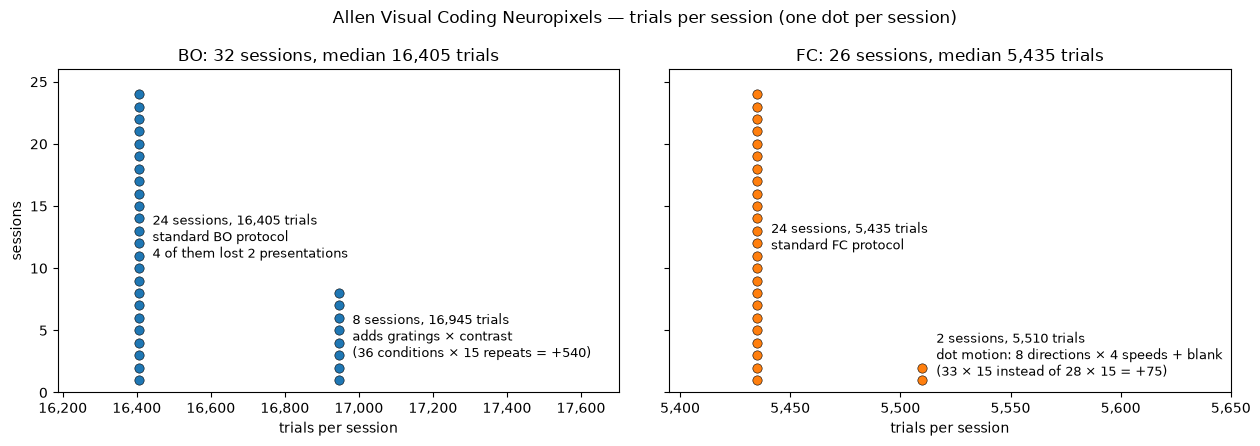

In [12]:
dot_dirs = stimuli[stimuli.stimulus == "dot_motion"].groupby("session_id").Dir.nunique()
contrast_ids = set(stimuli.session_id[(stimuli.stimulus == "drifting_gratings_contrast") & (stimuli.type == BO)])
CAUSE = {  # why a session's trial count differs from the rest of its type
    BO: lambda sid: "adds gratings × contrast\n(36 conditions × 15 repeats = +540)" if sid in contrast_ids
                    else "standard BO protocol",
    FC: lambda sid: "dot motion: 8 directions × 4 speeds + blank\n(33 × 15 instead of 28 × 15 = +75)"
                    if dot_dirs.get(sid) == 8
                    else "standard FC protocol",
}
by_cause = sessions.assign(cause=[CAUSE[t](sid) for t, sid in zip(sessions.session_type, sessions.session_id)])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, t in zip(axes, (BO, FC)):
    d = by_cause[by_cause.session_type == t]
    for cause, g in d.groupby("cause"):
        x = g.trials.max()
        ax.scatter(np.full(len(g), x), np.arange(1, len(g) + 1), s=45, color=TYPE_COLOR[t], edgecolor="k", lw=0.4)
        lost = (x - g.trials[g.trials < x]).unique()
        note = f"\n{(g.trials < x).sum()} of them lost {', '.join(map(str, sorted(lost)))} presentations" if len(lost) else ""
        ax.annotate(f"{len(g)} sessions, {x:,} trials\n{cause}{note}", (x, max(len(g) / 2 + 0.5, 3)),
                    xytext=(10, 0), textcoords="offset points", va="center", fontsize=9)
    lo, hi = d.trials.min(), d.trials.max()
    w = max(hi - lo, 100)
    ax.set(xlim=(lo - 0.4 * w, hi + 1.4 * w), xlabel="trials per session",
           title=f"{SHORT[t]}: {len(d)} sessions, median {half_up(d.trials.median()):,} trials")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set(ylabel="sessions", ylim=(0, 26))
fig.suptitle("Allen Visual Coding Neuropixels — trials per session (one dot per session)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "allen_trials_per_session.png", dpi=150)
plt.show()

### Brain regions

- Units per structure (CCF acronym of each unit's peak channel), top 30 by unit count.
- `grey` = in the brain but not assigned to a structure.
- Blank = the unit's peak channel has no structure label.
  - A few units on many probes, mostly near the top of the shank.
  - No probe is entirely blank.
- The probes aim at the visual system. So most units are in visual cortex, the hippocampus below it, and the
  thalamus below that.

| Group | Acronyms in the figure |
|---|---|
| Visual cortex | VISp primary visual; VISl lateral, VISli laterointermediate, VISal anterolateral, VISrl rostrolateral, VISam anteromedial, VISpm posteromedial, VISmma mediomedial anterior (higher visual areas); VIS = visual cortex, area not resolved |
| Hippocampus | CA1, CA3, DG dentate gyrus, SUB subiculum, ProS prosubiculum |
| Visual thalamus | LGd dorsal lateral geniculate (retina → cortex relay), LGv ventral lateral geniculate, LP lateral posterior (mouse pulvinar), POL posterior limiting nucleus |
| Other thalamus | TH thalamus (unresolved), VPM ventral posteromedial (whiskers), PO posterior complex, MGv / MGd medial geniculate (auditory), SGN suprageniculate, Eth ethmoid |
| Midbrain | APN anterior pretectal nucleus, NOT nucleus of the optic tract, MB midbrain (unresolved) |

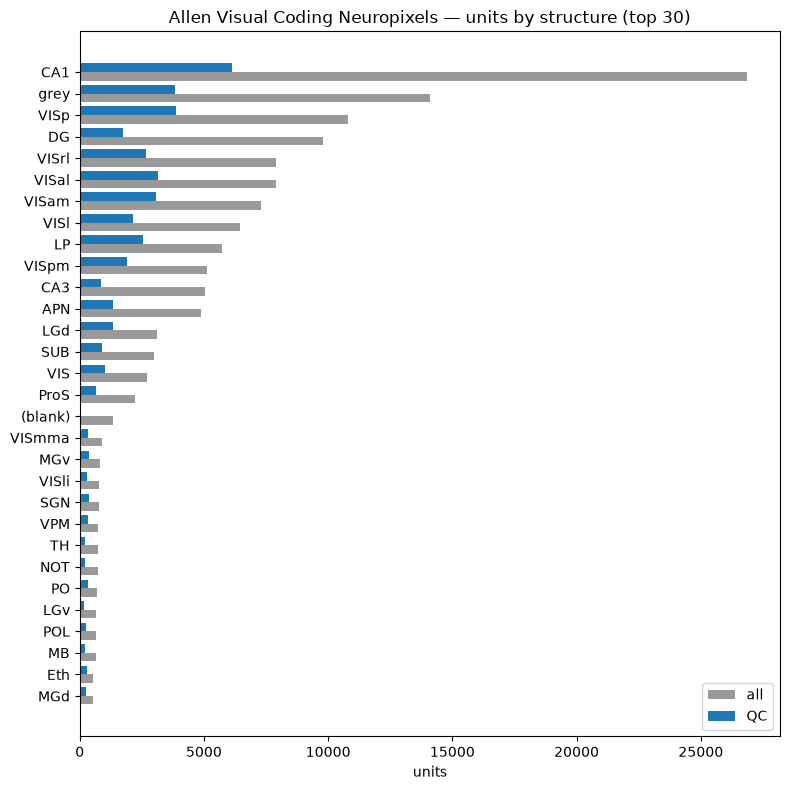

61 structures; visual cortex (VIS*) 50,211 units (18,534 QC)


In [13]:
region = units.region.replace("", "(blank)")
reg = pd.DataFrame({"all": region.value_counts(), "QC": region[units.qc].value_counts()}).fillna(0).astype(int)
reg = reg.sort_values("all").tail(30)
fig, ax = plt.subplots(figsize=(8, 8))
y = np.arange(len(reg))
ax.barh(y - 0.2, reg["all"], height=0.4, color="0.6", label="all")
ax.barh(y + 0.2, reg["QC"], height=0.4, color="C0", label="QC")
ax.set(yticks=y, yticklabels=reg.index, xlabel="units",
       title="Allen Visual Coding Neuropixels — units by structure (top 30)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "allen_regions.png", dpi=150)
plt.show()
visual = units.region.str.startswith("VIS")
print(f"{units.region.nunique()} structures; visual cortex (VIS*) {visual.sum():,} units ({visual[units.qc].sum():,} QC)")

### Raster

- An example BO session near the middle of the unit counts: 739448407, 647 QC units (the BO median is 682).
- 30 s, starting 5 s before its first flash.
- Rows = QC units, grouped by probe and sorted by depth (tip at the bottom).
- **Shaded bands**: 250 ms full-field flashes, one every 2 s.
  - Yellow = the screen turns white. Purple = the screen turns black.
  - Before the first flash (0–5 s), the screen is gray.
  - Each flash is one trial.
- **Blue horizontal lines**: boundaries between probes (probe names on the right).
  - Each probe is a separate shank in a different part of the visual system.
  - All probes record at the same time.

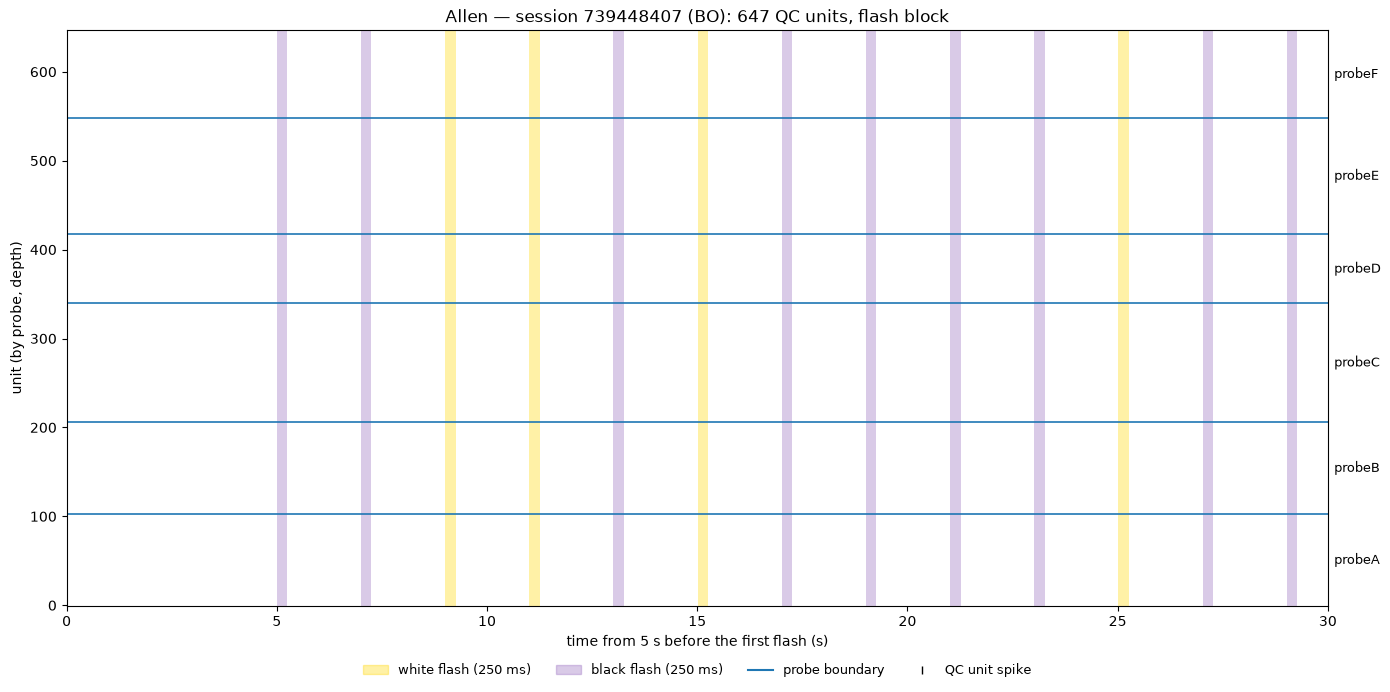

In [14]:
r = np.load(TABLES / "raster.npz")
sid = int(r["session_id"])
s = sessions.set_index("session_id").loc[sid]
u = units[units.session_id == sid].reset_index(drop=True)
assert (u.unit_id.to_numpy() == r["unit_id"]).all()
u["nwb_row"] = np.arange(len(u))
shown = u[u.qc].sort_values(["probe", "depth_um"]).reset_index(drop=True)
shown["row"] = np.arange(len(shown))
spk = pd.DataFrame({"nwb_row": r["unit_row"], "t": r["times"]}).merge(
    shown[["nwb_row", "row"]], on="nwb_row", how="inner")

fig, ax = plt.subplots(figsize=(14, 7))
for on, color in zip(r["flash_on"], r["flash_color"]):
    ax.axvspan(on, on + 0.25, color="gold" if color > 0 else "C4", alpha=0.35, lw=0)
ax.scatter(spk.t, spk.row, s=0.3, color="k", marker="|", linewidths=0.4, rasterized=True)
for p, grp in shown.groupby("probe"):
    if grp.row.max() < len(shown) - 1:
        ax.axhline(grp.row.max() + 0.5, color="C0", lw=1.2)
    ax.text(float(r["window_s"]) * 1.005, grp.row.mean(), p, va="center", fontsize=9)
ax.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color="gold", alpha=0.35, label="white flash (250 ms)"),
    plt.Rectangle((0, 0), 1, 1, color="C4", alpha=0.35, label="black flash (250 ms)"),
    plt.Line2D([], [], color="C0", lw=1.5, label="probe boundary"),
    plt.Line2D([], [], color="k", marker="|", ls="", label="QC unit spike"),
], loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=9, frameon=False)
ax.set(xlim=(0, float(r["window_s"])), ylim=(-0.5, len(shown) - 0.5),
       xlabel="time from 5 s before the first flash (s)", ylabel="unit (by probe, depth)",
       title=f"Allen — session {sid} ({SHORT[s.session_type]}): {len(shown):,} QC units, flash block")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "allen_raster.png", dpi=150)
plt.show()

## Spreadsheet

- Same columns as the NLB / FALCON / IBL CSVs.
- One totals row per session type, then one row per stimulus of that type.
- **CHANNELS**: `N/A` (sorted units).
- **Stimulus rows**:
  - **SUBJECTS**: sessions that show the stimulus.
  - **TRIALS**: its presentations.
  - **NEURONS**: QC units of those sessions (every unit is recorded through the whole session).
  - **LENGTH**: its time, as in the trials table.
  - **RAW**: blank (one NWB holds a whole session).
  - **NOTES**: its conditions.
  - **BENCHMARK**: the sum of three parts:
    - QC-unit spike times inside the stimulus's blocks, counted per session from the NWBs
      (`stim_spikes.parquet` from `data/allen/allen_stim_spikes.py`);
    - each session's non-spike data (NWB tables, running, eye tracking, metric CSVs), scaled by the
      stimulus's share of the recording;
    - the templates the stimulus shows.
  - Spontaneous activity and the gaps between blocks are in no stimulus row.
- **Precision**: LENGTH to 1 decimal (minutes); RAW / BENCHMARK to 3 decimals (GB).
- This cell writes `tutorials/allen_datasets.csv`.

In [16]:
templates = bucket[bucket.kind == "templates"]
template_gb = {
    BO: templates.bytes.sum() / GB,  # natural scenes + movies one and three
    FC: templates.bytes[templates.key.str.endswith("natural_movie_1.h5")].sum() / GB,
}
TEMPLATE_KEY = {  # template files each stimulus shows
    "natural_scenes": "natural_scene_templates/", "natural_movie_one": "natural_movie_1.h5",
    "natural_movie_one_more_repeats": "natural_movie_1.h5", "natural_movie_one_shuffled": "natural_movie_1.h5",
    "natural_movie_three": "natural_movie_3.h5",
}
stim_spikes = pd.read_parquet(TABLES / "stim_spikes.parquet")  # QC spikes inside each stimulus's blocks
stim_spikes = stim_spikes.set_index(["stimulus", "session_id"]).qc_spikes
store = storage.set_index("session_id")
store["type"] = session_type
bytes_per_spike = store.spike_times.sum() / sessions.spikes.sum()
qc_spikes = units[units.qc].groupby("session_id").spike_count.sum()
store["qc_spike_bytes"] = qc_spikes.reindex(store.index).fillna(0) * bytes_per_spike
metric_bytes = bucket[bucket.kind == "session_metrics"].groupby("session_id").bytes.sum()
store["non_spike"] = store.other + metric_bytes.reindex(store.index).fillna(0)
store["build"] = store.qc_spike_bytes + store.non_spike  # per-session part of the build
by_session = sessions.set_index("session_id")


def stimulus_row(t, stim):
    d = per_session.loc[(t, stim)]
    ids = d.index
    spike_bytes = stim_spikes[stim][ids].sum() * bytes_per_spike
    share = d.minutes * 60 / by_session.recording_s[ids]
    template = templates.bytes[templates.key.str.contains(TEMPLATE_KEY[stim], regex=False)].sum() \
        if stim in TEMPLATE_KEY else 0
    q = by_session.qc_units[ids]
    return {
        "DATASET": f"Allen VCN {SHORT[t]}: {STIM_LABEL[stim]}",
        "ANIMAL": "Mouse",
        "SUBJECTS": len(ids),
        "TRIALS": int(d.trials.sum()),
        "TOTAL CHANNELS": "N/A",
        "MEDIAN CHANNELS": "N/A",
        "TOTAL NEURONS": int(q.sum()),
        "MEDIAN NEURONS": half_up(q.median()),
        "RECORDING LENGTH (min)": round(d.minutes.sum(), 1),
        "RAW DATASET SIZE (GB)": "",
        "BENCHMARK DATASET SIZE (GB)": round((spike_bytes + (store.non_spike[ids] * share).sum() + template) / GB, 3),
        "NOTES": f"{STIM_WHAT[stim]}. Per session: {usual(d.conditions)} condition{'s' * bool(d.conditions.max() > 1)} × "
                 f"{repeats_text(d, ' repeats')}, {d.trial_s.median():.3g} s each. Benchmark size = QC-unit spike times "
                 f"inside this stimulus's blocks + each session's non-spike data × this stimulus's share of the "
                 f"recording + the stimulus templates it shows.",
        "BASIC STATS": "",
    }


rows = []
for t, name in [(BO, "Allen VCN Brain Observatory"), (FC, "Allen VCN Functional Connectivity")]:
    s, u, b = sessions[sessions.session_type == t], units[units.type == t], bucket[bucket.type == t]
    st = trial_stims[trial_stims.type == t].stimulus.value_counts().reindex(STIM_ORDER).dropna().astype(int)
    stim_text = ", ".join(f"{k} {v:,}" for k, v in st.items())
    fr_t, fr_tq = u.firing_rate, u.firing_rate[u.qc]
    raw_gb = b.bytes.sum() / GB
    bench_gb = store.build[store.type == t].sum() / GB + template_gb[t]
    draft_note = ("Draft Table 8 (inferred; the draft's unit rule and session IDs are not recorded): Flash BO top is most likely session 757216464, the BO session with the most QC units; BO drifting one TF has the same 959 neurons, so presumably the same session."
                  if t == BO else
                  "Draft Table 8 (inferred; the draft's unit rule and session IDs are not recorded): Flash FC top and second are most likely sessions 794812542 and 771160300, the FC sessions with the most QC units.")
    notes = (
        f"Allen Brain Observatory Visual Coding Neuropixels, {SHORT[t]} session type: {len(s)} sessions, one per mouse "
        f"({s.genotype.eq('wt/wt').sum()} wild type, {(~s.genotype.eq('wt/wt')).sum()} Cre;Ai32 opto-tagging lines); "
        f"passive viewing, head-fixed on a running wheel; {int(s.probes.sum())} Neuropixels 1.0 probes "
        f"({int(s.probes.min())}–{int(s.probes.max())} per session); CHANNELS N/A because units are sorted (Kilosort2). "
        f"NEURONS = AllenSDK default QC units (not noise & ISI violations < 0.5 & amplitude cutoff < 0.1 & "
        f"presence ratio > 0.9); all NWB units {len(u):,} (median {half_up(s.units.median())}/session). "
        f"TRIALS = stimulus presentations, movies counted per repeat, spontaneous excluded: {stim_text}. "
        f"LENGTH = first-to-last spike per session, summed ({s.recording_s.sum() / 3600:,.1f} h). "
        f"RAW = bucket files for these sessions: session NWBs {b.bytes[b.kind == 'session_nwb'].sum() / GB:.1f} GB + "
        f"LFP {b.bytes[b.kind == 'lfp'].sum() / GB:.1f} GB + unit metric CSVs {b.bytes[b.kind == 'session_metrics'].sum() / GB:.3f} GB "
        f"(no raw 30 kHz voltage is public). "
        f"BENCHMARK = QC-unit spike times ({store.qc_spike_bytes[store.type == t].sum() / GB:.1f} GB) + NWB stimulus "
        f"tables, unit metadata, running and eye tracking (eye tracking in {int(s.has_eye_tracking.sum())} of {len(s)} sessions; "
        f"{store.other[store.type == t].sum() / GB:.1f} GB) + unit metric CSVs and stimulus templates "
        f"({(b.bytes[b.kind == 'session_metrics'].sum() / GB + template_gb[t]):.2f} GB); per-spike amplitudes and mean waveforms dropped; "
        f"all-unit spike times would be {store.spike_times[store.type == t].sum() / GB:.1f} GB. " + draft_note
    )
    rows.append({
        "DATASET": name,
        "ANIMAL": "Mouse",
        "SUBJECTS": s.specimen_id.nunique(),
        "TRIALS": int(s.trials.sum()),
        "TOTAL CHANNELS": "N/A",
        "MEDIAN CHANNELS": "N/A",
        "TOTAL NEURONS": int(s.qc_units.sum()),
        "MEDIAN NEURONS": half_up(s.qc_units.median()),
        "RECORDING LENGTH (min)": round(s.recording_s.sum() / 60, 1),
        "RAW DATASET SIZE (GB)": round(raw_gb, 3),
        "BENCHMARK DATASET SIZE (GB)": round(bench_gb, 3),
        "NOTES": notes,
        "BASIC STATS": (f"QC-unit firing rate: mean {fr_tq.mean():.2f}, median {fr_tq.median():.2f} spikes/s "
                        f"(all units: mean {fr_t.mean():.2f}, median {fr_t.median():.2f})"),
    })
    rows += [stimulus_row(t, stim) for stim in STIM_ORDER[:-1] if (t, stim) in per_session.index.droplevel(2)]
inventory = pd.DataFrame(rows)
assert inventory.groupby(inventory.DATASET.str.contains(":")).TRIALS.sum().nunique() == 1  # stimulus rows add up
display(inventory.drop(columns=["NOTES", "BASIC STATS"]).set_index("DATASET"))
for n in inventory.NOTES:
    print(n, "\n")
csv_path = REPO / "tutorials" / "allen_datasets.csv"
inventory.to_csv(csv_path, index=False)
print("wrote", csv_path)

,ANIMAL,SUBJECTS,TRIALS,TOTAL CHANNELS,MEDIAN CHANNELS,TOTAL NEURONS,MEDIAN NEURONS,RECORDING LENGTH (min),RAW DATASET SIZE (GB),BENCHMARK DATASET SIZE (GB)
DATASET,,,,,,,,,,
Allen VCN Brain Observatory,Mouse,32,529272,N/A,N/A,22638,682,5242.0,477.616,18.927
Allen VCN BO: flashes,Mouse,32,4800,N/A,N/A,22638,682,159.2,,0.478
Allen VCN BO: drifting gratings,Mouse,32,20152,N/A,N/A,22638,682,1006.8,,3.389
Allen VCN BO: gratings × contrast,Mouse,8,4320,N/A,N/A,5343,641,72.0,,0.251
Allen VCN BO: static gratings,Mouse,32,192000,N/A,N/A,22638,682,800.7,,2.876
Allen VCN BO: gabors,Mouse,32,116640,N/A,N/A,22638,682,486.4,,1.419
Allen VCN BO: natural scenes,Mouse,32,190400,N/A,N/A,22638,682,794.0,,3.055
Allen VCN BO: natural movie one,Mouse,32,640,N/A,N/A,22638,682,320.3,,1.319
Allen VCN BO: natural movie three,Mouse,32,320,N/A,N/A,22638,682,640.5,,2.940


Allen Brain Observatory Visual Coding Neuropixels, BO session type: 32 sessions, one per mouse (16 wild type, 16 Cre;Ai32 opto-tagging lines); passive viewing, head-fixed on a running wheel; 183 Neuropixels 1.0 probes (4–6 per session); CHANNELS N/A because units are sorted (Kilosort2). NEURONS = AllenSDK default QC units (not noise & ISI violations < 0.5 & amplitude cutoff < 0.1 & presence ratio > 0.9); all NWB units 74,658 (median 2292/session). TRIALS = stimulus presentations, movies counted per repeat, spontaneous excluded: flashes 4,800, drifting_gratings 20,152, drifting_gratings_contrast 4,320, static_gratings 192,000, gabors 116,640, natural_scenes 190,400, natural_movie_one 640, natural_movie_three 320. LENGTH = first-to-last spike per session, summed (87.4 h). RAW = bucket files for these sessions: session NWBs 80.5 GB + LFP 397.1 GB + unit metric CSVs 0.053 GB (no raw 30 kHz voltage is public). BENCHMARK = QC-unit spike times (14.0 GB) + NWB stimulus tables, unit metadata, r